# SAFE-PRED 2.0: Feature-Criticality-Aware Selective Prediction for Heart-Disease AI

**Publication-oriented, leakage-controlled Kaggle notebook**

This notebook keeps the original Cleveland→Hungarian SAFE-PRED study and adds the analyses needed to test a stronger novelty: **does knowing which clinical information is missing improve safe deferral beyond uncertainty and generic missingness alone?**

### Cohorts
- Development/internal validation: **UCI Cleveland Heart Disease**
- Cross-center evaluation: **UCI Hungarian Heart Disease**
- Source: official UCI Heart Disease repository (DOI: 10.24432/C52P4X)

### Added analyses
- single-feature leave-one-out degradation;
- Cleveland-derived Clinical Information Criticality;
- criticality transfer to Hungarian;
- high-vs-low criticality dropout at equal missingness;
- ensemble-disagreement baseline;
- original SAFE-PRED vs **Feature-Aware SAFE-PRED**;
- AURC and E-AURC;
- matched-coverage comparisons;
- paired bootstrap comparisons;
- high-confidence-error capture;
- fairness bootstrap confidence intervals;
- exploratory Operational Reliability / Safe Automation Envelope;
- automatic export and ZIP creation.

All feature criticality weights, reliability weights, and thresholds are learned from **Cleveland only**. Hungarian labels are never used for tuning.

> “Safe automation” in this notebook is an experimental reliability criterion, not a clinical safety certification.


### Authoritative dataset provenance
The notebook downloads the processed Cleveland and Hungarian files directly from UCI. For publication, cite UCI and the original clinical contributors rather than Kaggle as the primary source.


In [1]:
print("PRE-FLIGHT STUDY DECISION")
print("- Development cohort: UCI Cleveland Heart Disease (n=303)")
print("- Cross-center cohort: UCI Hungarian Heart Disease (n=294)")
print("- Statlog excluded because it is not independent of Cleveland")
print("- Primary internal performance: nested stratified CV")
print("- Cross-center validation: Hungarian kept untouched during Cleveland model development")
print("- Full 13-feature analysis: Cleveland internal robustness")
print("- Core 10-feature analysis: Cleveland -> Hungarian transfer (slope/ca/thal excluded because of extreme Hungarian missingness)")
print("- Fairness audit: sex + age groups when subgroup n is adequate")
print("- No resampling/SMOTE is used by default; class balance is reported instead")

PRE-FLIGHT STUDY DECISION
- Development cohort: UCI Cleveland Heart Disease (n=303)
- Cross-center cohort: UCI Hungarian Heart Disease (n=294)
- Statlog excluded because it is not independent of Cleveland
- Primary internal performance: nested stratified CV
- Cross-center validation: Hungarian kept untouched during Cleveland model development
- Full 13-feature analysis: Cleveland internal robustness
- Core 10-feature analysis: Cleveland -> Hungarian transfer (slope/ca/thal excluded because of extreme Hungarian missingness)
- Fairness audit: sex + age groups when subgroup n is adequate
- No resampling/SMOTE is used by default; class balance is reported instead


## 1. Imports and reproducibility
The random seed is fixed. All train-dependent preprocessing is embedded in scikit-learn `Pipeline`/`ColumnTransformer` objects so imputers, scalers and encoders are fitted only on training folds.


In [2]:
import os, sys, json, math, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    recall_score,
    confusion_matrix, matthews_corrcoef, brier_score_loss,
    roc_curve, precision_recall_curve, accuracy_score, precision_score,
    recall_score, f1_score
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr, ks_2samp

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.bbox'] = 'tight'
OUT = Path('/kaggle/working/safe_pred_outputs') if Path('/kaggle/working').exists() else Path('./safe_pred_outputs')
OUT.mkdir(parents=True, exist_ok=True)
print('Output directory:', OUT)
# Optional supplementary boosted-tree baselines (Kaggle normally includes both).
HAS_XGB = False
HAS_LGBM = False
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    pass
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except Exception:
    pass


Output directory: /kaggle/working/safe_pred_outputs


## 2. Load both cohorts directly from UCI
Kaggle must have **Internet enabled** for these URLs. The code uses the official UCI raw files, not a third-party Kaggle mirror.


In [3]:
CLEVELAND_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
HUNGARIAN_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.hungarian.data'

COLS = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','num']


def load_uci_raw(url):
    df = pd.read_csv(url, header=None, names=COLS, na_values='?')
    for c in COLS:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

cleveland_raw = load_uci_raw(CLEVELAND_URL)
hungarian_raw = load_uci_raw(HUNGARIAN_URL)

print('Cleveland shape :', cleveland_raw.shape)
print('Hungarian shape :', hungarian_raw.shape)
assert cleveland_raw.shape[1] == 14 and hungarian_raw.shape[1] == 14
assert len(cleveland_raw) == 303, 'Unexpected Cleveland row count'
assert len(hungarian_raw) == 294, 'Unexpected Hungarian row count'

Cleveland shape : (303, 14)
Hungarian shape : (294, 14)


## 3. Harmonize target and audit provenance-sensitive overlap
UCI Cleveland/Hungarian `num` uses 0 for no disease and values 1–4 for disease. We binarize with `num > 0`.  
We also perform an **exact feature-overlap audit**. If identical feature vectors appear in both cohorts, they are removed from the external cohort before any final cross-center evaluation.


In [4]:
FEATURES_13 = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal']
CORE_10 = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak']
NUMERIC_13 = ['age','trestbps','chol','thalach','oldpeak']
CATEGORICAL_13 = [c for c in FEATURES_13 if c not in NUMERIC_13]
NUMERIC_10 = [c for c in NUMERIC_13 if c in CORE_10]
CATEGORICAL_10 = [c for c in CORE_10 if c not in NUMERIC_10]


def harmonize(df, cohort):
    z = df.copy()
    z['target'] = (z['num'] > 0).astype(int)
    z['cohort'] = cohort
    return z

cleveland = harmonize(cleveland_raw, 'Cleveland')
hungarian = harmonize(hungarian_raw, 'Hungarian')

# Exact overlap on 13-feature records, treating missingness consistently.
left = cleveland[FEATURES_13].copy().fillna(-999999)
right = hungarian[FEATURES_13].copy().fillna(-999999)
left_keys = set(map(tuple, left.to_numpy()))
external_overlap_mask = right.apply(lambda r: tuple(r.to_numpy()) in left_keys, axis=1)
print('Exact Cleveland-feature duplicates inside Hungarian:', int(external_overlap_mask.sum()))
if external_overlap_mask.any():
    print('Removing overlapping external rows before validation.')
    hungarian = hungarian.loc[~external_overlap_mask].reset_index(drop=True)
print('External rows retained:', len(hungarian))

Exact Cleveland-feature duplicates inside Hungarian: 0
External rows retained: 294


## 4. Dataset audit
This section checks class balance, missingness, unique category codes, implausible ranges and cohort differences **before** modelling.


In [5]:
def audit_table(df, name):
    return pd.DataFrame({
        'cohort':[name],
        'n':[len(df)],
        'positive_n':[int(df.target.sum())],
        'positive_pct':[100*df.target.mean()],
        'missing_cells':[int(df[FEATURES_13].isna().sum().sum())],
        'missing_pct':[100*df[FEATURES_13].isna().mean().mean()],
        'female_n':[int((df.sex==0).sum())],
        'male_n':[int((df.sex==1).sum())],
    })

audit = pd.concat([audit_table(cleveland,'Cleveland'), audit_table(hungarian,'Hungarian')], ignore_index=True)
display(audit.round(2))

miss = pd.DataFrame({
    'Cleveland_missing_n': cleveland[FEATURES_13].isna().sum(),
    'Cleveland_missing_pct': 100*cleveland[FEATURES_13].isna().mean(),
    'Hungarian_missing_n': hungarian[FEATURES_13].isna().sum(),
    'Hungarian_missing_pct': 100*hungarian[FEATURES_13].isna().mean(),
}).sort_values('Hungarian_missing_pct', ascending=False)
display(miss.round(2))

print('Categorical codes:')
for c in CATEGORICAL_13:
    print(c, 'Cleveland=', sorted(cleveland[c].dropna().unique().tolist()), 'Hungarian=', sorted(hungarian[c].dropna().unique().tolist()))

,cohort,n,positive_n,positive_pct,missing_cells,missing_pct,female_n,male_n
0,Cleveland,303,139,45.87,6,0.15,97,206
1,Hungarian,294,106,36.05,782,20.46,81,213


,Cleveland_missing_n,Cleveland_missing_pct,Hungarian_missing_n,Hungarian_missing_pct
ca,4,1.32,291,98.98
thal,2,0.66,266,90.48
slope,0,0.00,190,64.63
chol,0,0.00,23,7.82
fbs,0,0.00,8,2.72
exang,0,0.00,1,0.34
thalach,0,0.00,1,0.34
restecg,0,0.00,1,0.34
trestbps,0,0.00,1,0.34
sex,0,0.00,0,0.00


Categorical codes:
sex Cleveland= [0.0, 1.0] Hungarian= [0, 1]
cp Cleveland= [1.0, 2.0, 3.0, 4.0] Hungarian= [1, 2, 3, 4]
fbs Cleveland= [0.0, 1.0] Hungarian= [0.0, 1.0]
restecg Cleveland= [0.0, 1.0, 2.0] Hungarian= [0.0, 1.0, 2.0]
exang Cleveland= [0.0, 1.0] Hungarian= [0.0, 1.0]
slope Cleveland= [1.0, 2.0, 3.0] Hungarian= [1.0, 2.0, 3.0]
ca Cleveland= [0.0, 1.0, 2.0, 3.0] Hungarian= [0.0]
thal Cleveland= [3.0, 6.0, 7.0] Hungarian= [3.0, 6.0, 7.0]


### Figure 1 — class distribution


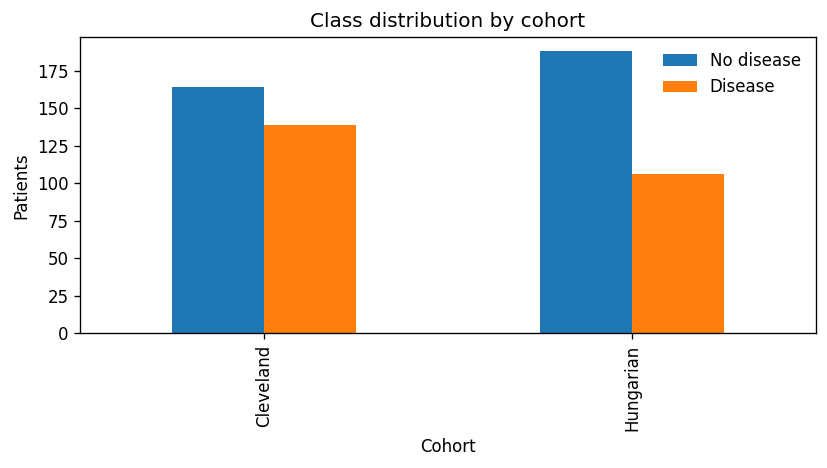

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
summary = pd.DataFrame({
    'Cleveland': cleveland.target.value_counts().sort_index(),
    'Hungarian': hungarian.target.value_counts().sort_index()
}).T
summary.columns = ['No disease','Disease']
summary.plot(kind='bar', ax=ax)
ax.set_ylabel('Patients'); ax.set_xlabel('Cohort'); ax.set_title('Class distribution by cohort')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(OUT/'fig01_class_distribution.png', dpi=300); plt.show()

### Figure 2 — feature missingness by cohort


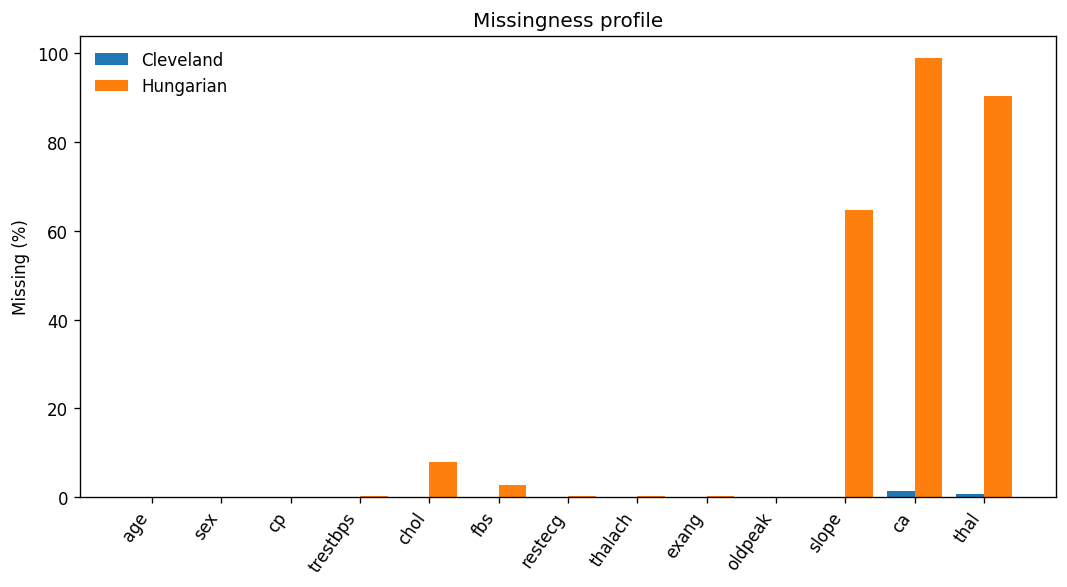

In [7]:
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(len(FEATURES_13)); w=0.4
ax.bar(x-w/2, 100*cleveland[FEATURES_13].isna().mean(), width=w, label='Cleveland')
ax.bar(x+w/2, 100*hungarian[FEATURES_13].isna().mean(), width=w, label='Hungarian')
ax.set_xticks(x); ax.set_xticklabels(FEATURES_13, rotation=55, ha='right')
ax.set_ylabel('Missing (%)'); ax.set_title('Missingness profile')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(OUT/'fig02_missingness.png', dpi=300); plt.show()

### Figures 3–4 — continuous-feature distributions and correlation structure


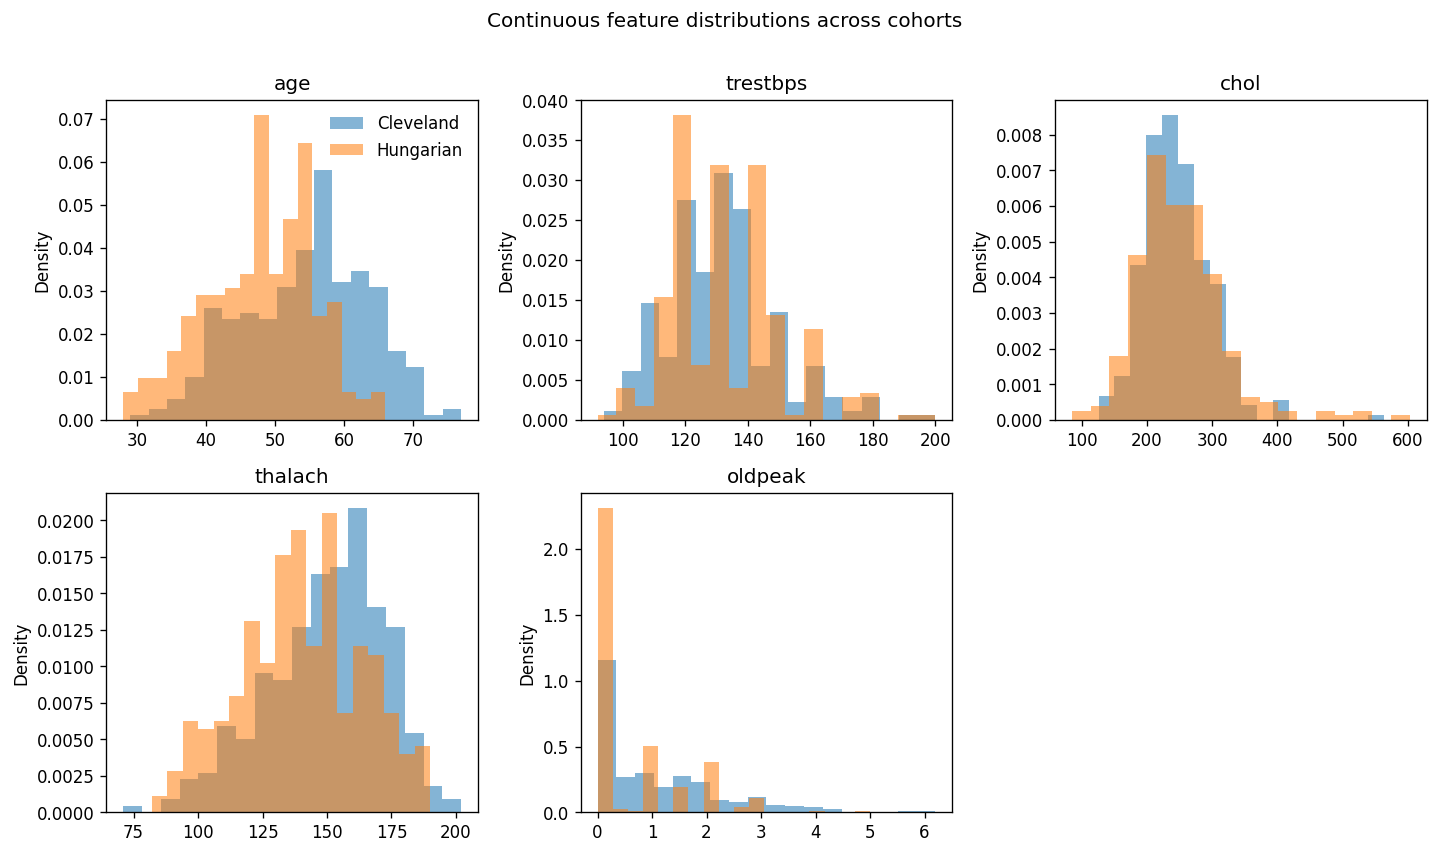

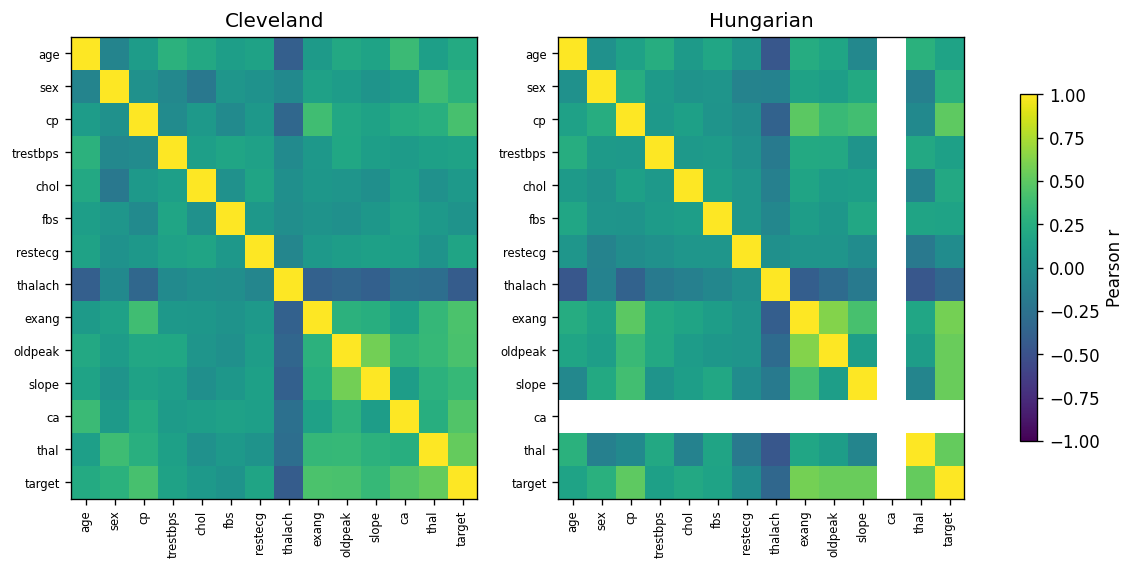

In [8]:
continuous = NUMERIC_13
fig, axes = plt.subplots(2,3, figsize=(12,7))
axes = axes.ravel()
for i,c in enumerate(continuous):
    axes[i].hist(cleveland[c].dropna(), bins=18, alpha=.55, density=True, label='Cleveland')
    axes[i].hist(hungarian[c].dropna(), bins=18, alpha=.55, density=True, label='Hungarian')
    axes[i].set_title(c); axes[i].set_ylabel('Density')
axes[0].legend(frameon=False)
axes[-1].axis('off')
plt.suptitle('Continuous feature distributions across cohorts', y=1.01)
plt.tight_layout(); plt.savefig(OUT/'fig03_continuous_distributions.png', dpi=300); plt.show()

fig, axes = plt.subplots(1,2, figsize=(12,5))
for ax, df, name in [(axes[0],cleveland,'Cleveland'), (axes[1],hungarian,'Hungarian')]:
    corr = df[FEATURES_13+['target']].corr(numeric_only=True)
    im=ax.imshow(corr, vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
    ax.set_title(name)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.75, label='Pearson r')
plt.savefig(OUT/'fig04_correlations.png', dpi=300); plt.show()

## 5. Cross-center shift audit
Numeric variables use Kolmogorov–Smirnov statistics. Categorical variables use total-variation distance. These are descriptive shift diagnostics, not hypothesis tests for model selection.


,feature,measure,shift
6,restecg,TV,0.468
0,age,KS,0.355
9,oldpeak,KS,0.316
7,thalach,KS,0.261
2,cp,TV,0.196
5,fbs,TV,0.079
3,trestbps,KS,0.062
4,chol,KS,0.059
1,sex,TV,0.045
8,exang,TV,0.023


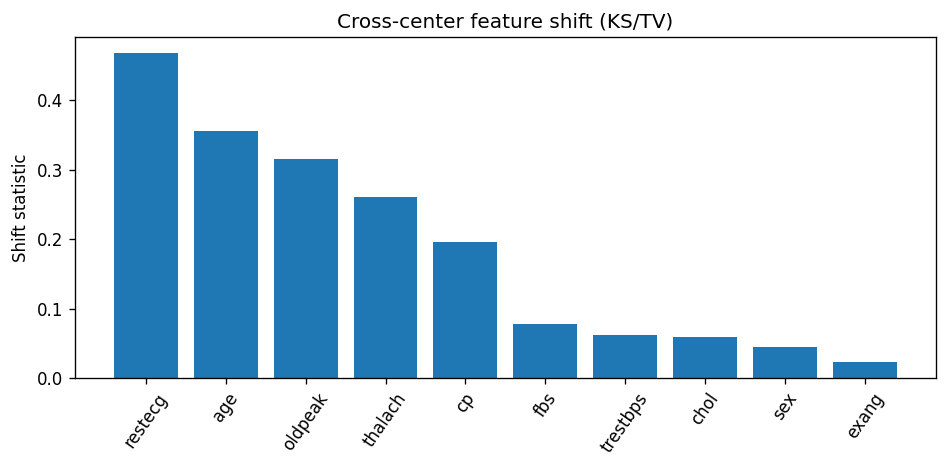

In [9]:
def tv_distance(a,b):
    cats = sorted(set(a.dropna().unique()).union(set(b.dropna().unique())))
    pa = a.value_counts(normalize=True).reindex(cats, fill_value=0)
    pb = b.value_counts(normalize=True).reindex(cats, fill_value=0)
    return 0.5*np.abs(pa-pb).sum()

rows=[]
for c in CORE_10:
    if c in NUMERIC_10:
        s = ks_2samp(cleveland[c].dropna(), hungarian[c].dropna()).statistic
        rows.append((c,'KS',s))
    else:
        rows.append((c,'TV',tv_distance(cleveland[c], hungarian[c])))
shift_df = pd.DataFrame(rows, columns=['feature','measure','shift']).sort_values('shift',ascending=False)
display(shift_df.round(3))

fig, ax=plt.subplots(figsize=(8,4))
ax.bar(shift_df.feature, shift_df['shift'])
ax.set_ylabel('Shift statistic'); ax.set_title('Cross-center feature shift (KS/TV)')
ax.tick_params(axis='x', rotation=55)
plt.tight_layout(); plt.savefig(OUT/'fig05_shift_audit.png', dpi=300); plt.show()

## 6. Leakage-free preprocessing factory
No imputation, scaling or encoding is performed before a split. All such steps are inside the pipeline fitted on each training fold.


In [10]:
def make_preprocessor(features):
    nums = [c for c in NUMERIC_13 if c in features]
    cats = [c for c in features if c not in nums]
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent', add_indicator=True)),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('num', num_pipe, nums),
        ('cat', cat_pipe, cats)
    ], remainder='drop', verbose_feature_names_out=False)


def model_space(features):
    pre = make_preprocessor(features)
    spaces = {
        'Logistic Regression': (
            Pipeline([('pre',pre),('clf',LogisticRegression(max_iter=4000, class_weight=None, random_state=SEED))]),
            {'clf__C':[0.05,0.2,1,5,20]}
        ),
        'SVM-RBF': (
            Pipeline([('pre',pre),('clf',SVC(probability=True, random_state=SEED))]),
            {'clf__C':[0.2,1,5,20], 'clf__gamma':['scale',0.01,0.1]}
        ),
        'Random Forest': (
            Pipeline([('pre',pre),('clf',RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
            {'clf__n_estimators':[300,600], 'clf__max_depth':[None,4,8], 'clf__min_samples_leaf':[1,3,5]}
        ),
        'Extra Trees': (
            Pipeline([('pre',pre),('clf',ExtraTreesClassifier(random_state=SEED, n_jobs=-1))]),
            {'clf__n_estimators':[300,600], 'clf__max_depth':[None,4,8], 'clf__min_samples_leaf':[1,3,5]}
        ),
        'Gradient Boosting': (
            Pipeline([('pre',pre),('clf',GradientBoostingClassifier(random_state=SEED))]),
            {'clf__n_estimators':[50,100,200], 'clf__learning_rate':[0.03,0.08,0.15], 'clf__max_depth':[1,2,3]}
        )
    }
    if HAS_XGB:
        spaces['XGBoost'] = (
            Pipeline([('pre',pre),('clf',XGBClassifier(
                random_state=SEED, eval_metric='logloss', n_jobs=-1,
                tree_method='hist', verbosity=0
            ))]),
            {'clf__n_estimators':[100,250], 'clf__max_depth':[2,3,5],
             'clf__learning_rate':[0.03,0.08,0.15], 'clf__subsample':[0.8,1.0],
             'clf__colsample_bytree':[0.8,1.0]}
        )
    if HAS_LGBM:
        spaces['LightGBM'] = (
            Pipeline([('pre',pre),('clf',LGBMClassifier(
                random_state=SEED, n_jobs=-1, verbosity=-1
            ))]),
            {'clf__n_estimators':[100,250], 'clf__num_leaves':[7,15,31],
             'clf__learning_rate':[0.03,0.08,0.15], 'clf__min_child_samples':[10,20,30]}
        )
    return spaces

print('Leakage-control check: preprocessing is nested inside every model pipeline.')


Leakage-control check: preprocessing is nested inside every model pipeline.


## 7. Nested CV baseline comparison on Cleveland (13 features)
Outer 5-fold CV estimates generalization. Inner 4-fold CV tunes hyperparameters. Each outer test fold is untouched by its inner search.


In [11]:
def binary_metrics(y, p, threshold=.5):
    pred=(np.asarray(p)>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {
        'AUROC':roc_auc_score(y,p),
        'AUPRC':average_precision_score(y,p),
        'BalancedAcc':balanced_accuracy_score(y,pred),
        'Sensitivity':tp/(tp+fn) if tp+fn else np.nan,
        'Specificity':tn/(tn+fp) if tn+fp else np.nan,
        'MCC':matthews_corrcoef(y,pred),
        'Brier':brier_score_loss(y,p)
    }


def nested_compare(X,y,features, outer_splits=5, inner_splits=4):
    outer=StratifiedKFold(n_splits=outer_splits,shuffle=True,random_state=SEED)
    spaces=model_space(features)
    rows=[]; oof={name:np.full(len(y),np.nan) for name in spaces}; best_params={name:[] for name in spaces}
    for fold,(tr,te) in enumerate(outer.split(X,y),1):
        Xtr,Xte=X.iloc[tr],X.iloc[te]; ytr,yte=y.iloc[tr],y.iloc[te]
        inner=StratifiedKFold(n_splits=inner_splits,shuffle=True,random_state=SEED+fold)
        for name,(pipe,grid) in spaces.items():
            gs=GridSearchCV(pipe,grid,scoring='roc_auc',cv=inner,n_jobs=-1,refit=True)
            gs.fit(Xtr[features],ytr)
            p=gs.predict_proba(Xte[features])[:,1]
            oof[name][te]=p
            m=binary_metrics(yte,p); m.update({'Model':name,'Fold':fold})
            rows.append(m); best_params[name].append(gs.best_params_)
    fold_df=pd.DataFrame(rows)
    summary=fold_df.groupby('Model').agg(['mean','std'])
    return fold_df,summary,oof,best_params

Xc=cleveland[FEATURES_13].copy(); yc=cleveland.target.copy()
fold13, summary13, oof13, params13 = nested_compare(Xc,yc,FEATURES_13)
display(summary13.round(3))
summary13.to_csv(OUT/'table_nested_cv_full13.csv')

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

AUROC         AUPRC        BalancedAcc         \
                      mean    std   mean    std        mean    std   
Model                                                                
Extra Trees          0.908  0.029  0.906  0.039       0.832  0.025   
Gradient Boosting    0.897  0.039  0.890  0.043       0.812  0.053   
LightGBM             0.896  0.016  0.890  0.022       0.818  0.026   
Logistic Regression  0.921  0.022  0.919  0.029       0.864  0.060   
Random Forest        0.918  0.024  0.917  0.033       0.838  0.026   
SVM-RBF              0.908  0.033  0.908  0.043       0.842  0.032   
XGBoost              0.902  0.024  0.900  0.026       0.828  0.046   

                    Sensitivity        Specificity           MCC         \
                           mean    std        mean    std   mean    std   
Model                                                                     
Extra Trees               0.791  0.033       0.872  0.049  0.669  0.052   
Gradient Boosting         0.776  0.081       0.848  0.067  0.630  0.107   
LightGBM                  0.770  0.061       0.866  0.066  0.644  0.052   
Logistic Regression       0.812  0.095       0.915  0.039  0.736  0.115   
Random Forest             0.791  0.042       0.884  0.032  0.681  0.052   
SVM-RBF                   0.842  0.055       0.842  0.058  0.685  0.066   
XGBoost                   0.784  0.060       0.872  0.069  0.663  0.092   

                     Brier        Fold         
                      mean    std mean    std  
Model                                          
Extra Trees          0.123  0.015  3.0  1.581  
Gradient Boosting    0.135  0.030  3.0  1.581  
LightGBM             0.133  0.018  3.0  1.581  
Logistic Regression  0.112  0.015  3.0  1.581  
Random Forest        0.124  0.010  3.0  1.581  
SVM-RBF              0.121  0.023  3.0  1.581  
XGBoost              0.128  0.025  3.0  1.581

### Figures 6–8 — model comparison, OOF ROC and PR curves


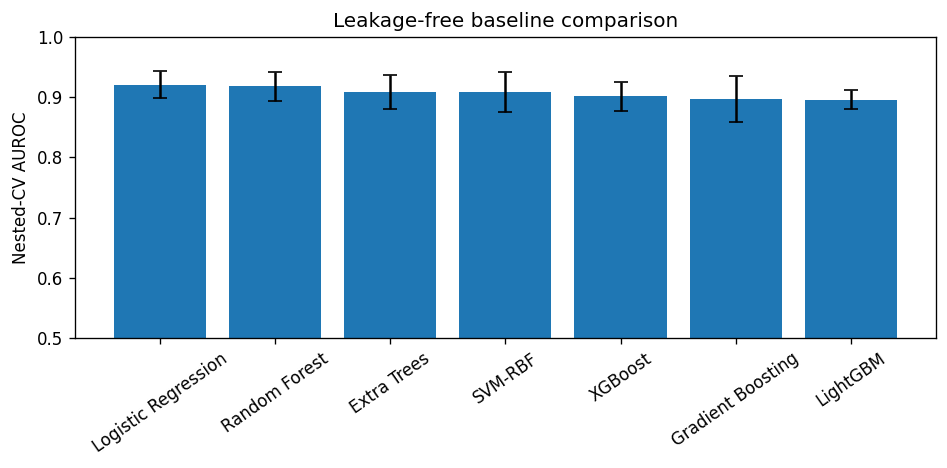

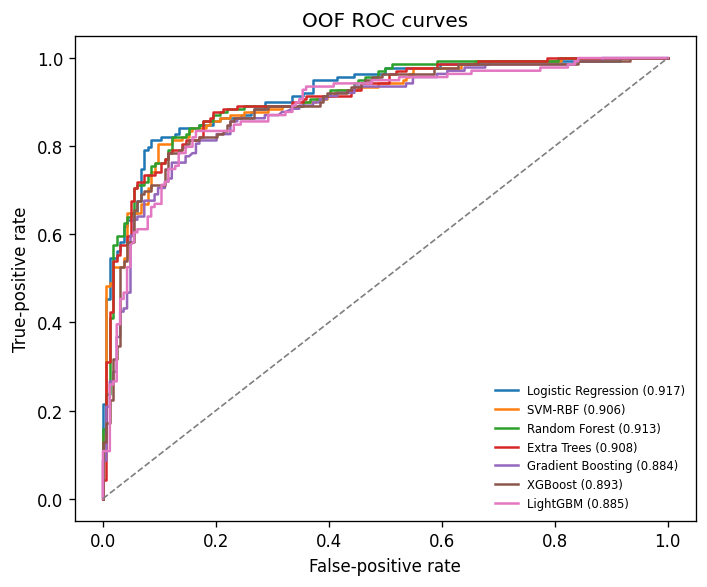

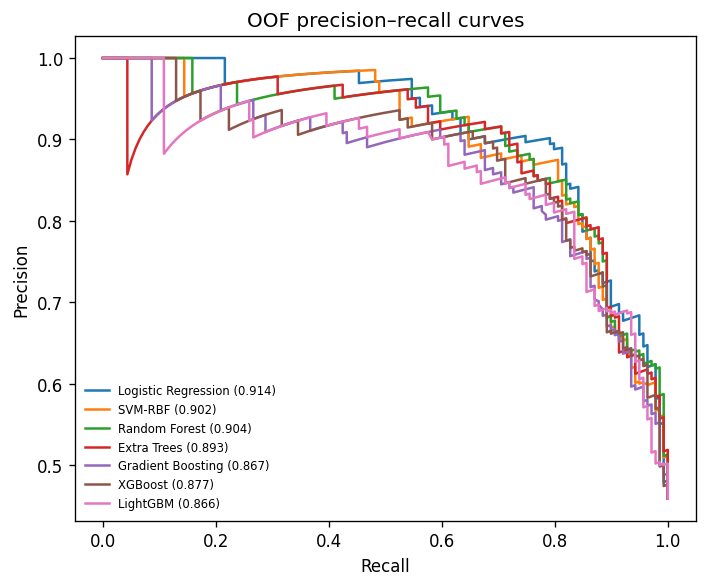

In [12]:
means=fold13.groupby('Model')['AUROC'].mean().sort_values(ascending=False)
stds=fold13.groupby('Model')['AUROC'].std().reindex(means.index)
fig,ax=plt.subplots(figsize=(8,4)); ax.bar(means.index,means.values,yerr=stds.values,capsize=4)
ax.set_ylim(.5,1); ax.set_ylabel('Nested-CV AUROC'); ax.set_title('Leakage-free baseline comparison')
ax.tick_params(axis='x',rotation=35); plt.tight_layout(); plt.savefig(OUT/'fig06_model_auroc.png',dpi=300); plt.show()

fig,ax=plt.subplots(figsize=(6,5))
for name,p in oof13.items():
    fpr,tpr,_=roc_curve(yc,p); ax.plot(fpr,tpr,label=f'{name} ({roc_auc_score(yc,p):.3f})')
ax.plot([0,1],[0,1],'--',linewidth=1); ax.set_xlabel('False-positive rate'); ax.set_ylabel('True-positive rate'); ax.set_title('OOF ROC curves')
ax.legend(fontsize=7,frameon=False); plt.tight_layout(); plt.savefig(OUT/'fig07_oof_roc.png',dpi=300); plt.show()

fig,ax=plt.subplots(figsize=(6,5))
for name,p in oof13.items():
    pr,rc,_=precision_recall_curve(yc,p); ax.plot(rc,pr,label=f'{name} ({average_precision_score(yc,p):.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('OOF precision–recall curves')
ax.legend(fontsize=7,frameon=False); plt.tight_layout(); plt.savefig(OUT/'fig08_oof_pr.png',dpi=300); plt.show()

## 8. Choose deployment model on Cleveland only
The Hungarian labels remain unseen. Model family/hyperparameters are chosen by CV on Cleveland. This fitted model is then calibrated using internal CV on Cleveland.


In [13]:
def choose_model_on_development(X,y,features):
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    records=[]; fitted={}
    for name,(pipe,grid) in model_space(features).items():
        gs=GridSearchCV(pipe,grid,scoring='roc_auc',cv=cv,n_jobs=-1,refit=True)
        gs.fit(X[features],y)
        records.append({'Model':name,'CV_AUROC':gs.best_score_,'BestParams':gs.best_params_})
        fitted[name]=gs.best_estimator_
    sel=pd.DataFrame(records).sort_values('CV_AUROC',ascending=False).reset_index(drop=True)
    best_name=sel.loc[0,'Model']; best_est=fitted[best_name]
    return sel,best_name,best_est

sel10,best_name10,best10 = choose_model_on_development(cleveland,cleveland.target,CORE_10)
display(sel10)
print('Selected development model for cross-center analysis:',best_name10)

# Probability calibration learned only from Cleveland.
calibrated10 = CalibratedClassifierCV(estimator=clone(best10), method='sigmoid', cv=5)
calibrated10.fit(cleveland[CORE_10],cleveland.target)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

,Model,CV_AUROC,BestParams
0,Logistic Regression,0.882489,{'clf__C': 1}
1,Random Forest,0.876710,"{'clf__max_depth': None, 'clf__min_samples_lea..."
2,Extra Trees,0.876595,"{'clf__max_depth': 8, 'clf__min_samples_leaf':..."
3,Gradient Boosting,0.873506,"{'clf__learning_rate': 0.15, 'clf__max_depth':..."
4,SVM-RBF,0.872013,"{'clf__C': 1, 'clf__gamma': 0.01}"
5,XGBoost,0.870481,"{'clf__colsample_bytree': 1.0, 'clf__learning_..."
6,LightGBM,0.862591,"{'clf__learning_rate': 0.03, 'clf__min_child_s..."


Selected development model for cross-center analysis: Logistic Regression


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('pre',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(add_indicator=True,
                                                                                                                  strategy='median')),
                                                                                                   ('scaler',
                                                                                                    StandardScaler())]),
                                                                                   ['age',
                                                                                    'trestbps',
                                                                                    'chol',
                                                                                    'thalach',
                                                                                    'oldpeak']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(add_indicator=True,
                                                                                                                  strategy='most_frequent')),
                                                                                                   ('onehot',
                                                                                                    OneHotEncoder(handle_unknown='ignore',
                                                                                                                  sparse_output=False))]),
                                                                                   ['sex',
                                                                                    'cp',
                                                                                    'fbs',
                                                                                    'restecg',
                                                                                    'exang'])],
                                                                    verbose_feature_names_out=False)),
                                                 ('clf',
                                                  LogisticRegression(C=1,
                                                                     max_iter=4000,
                                                                     random_state=42))]))

## 9. Calibrated OOF probabilities and calibration curve on Cleveland core-10
These OOF probabilities are used to derive the SAFE-PRED reliability threshold. Final external performance is still measured only on Hungarian.


AUROC          0.879
AUPRC          0.867
BalancedAcc    0.781
Sensitivity    0.727
Specificity    0.835
MCC            0.567
Brier          0.140
dtype: float64


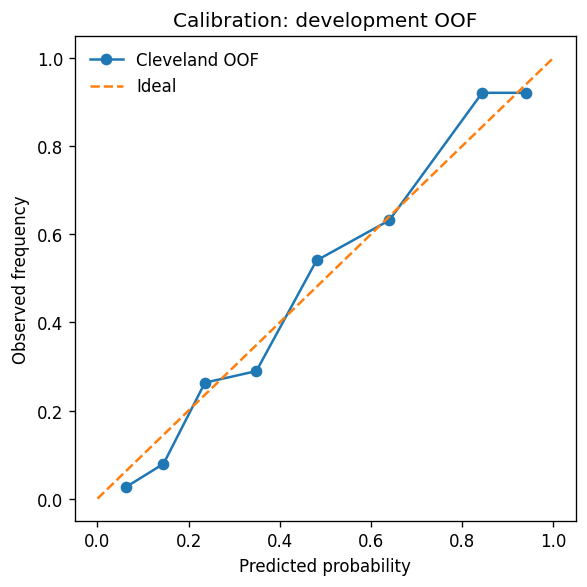

In [14]:
from sklearn.model_selection import cross_val_predict
cv5=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
# Fixed model specification chosen on development data; cross_val_predict prevents each patient's target entering its fitted predictor.
cal_template=CalibratedClassifierCV(estimator=clone(best10), method='sigmoid', cv=3)
p_oof10=cross_val_predict(cal_template, cleveland[CORE_10], cleveland.target, cv=cv5, method='predict_proba', n_jobs=-1)[:,1]
print(pd.Series(binary_metrics(cleveland.target,p_oof10)).round(3))

prob_true,prob_pred=calibration_curve(cleveland.target,p_oof10,n_bins=8,strategy='quantile')
fig,ax=plt.subplots(figsize=(5,5)); ax.plot(prob_pred,prob_true,'o-',label='Cleveland OOF'); ax.plot([0,1],[0,1],'--',label='Ideal')
ax.set_xlabel('Predicted probability'); ax.set_ylabel('Observed frequency'); ax.set_title('Calibration: development OOF')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(OUT/'fig09_calibration_oof.png',dpi=300); plt.show()

## 10. Controlled random degradation — leakage-free evaluation
Only test-fold feature values are degraded. Models are fitted on their corresponding clean training folds. Missingness is handled by train-fitted imputers inside the pipeline.


In [15]:
def degrade_random(X, frac, seed):
    z=X.copy(); rng=np.random.default_rng(seed)
    if frac<=0: return z
    mask=rng.random(z.shape)<frac
    z=z.mask(mask)
    return z


def cv_degradation(model_template, X, y, features, fracs=(0,.05,.10,.20,.30,.40)):
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    rows=[]
    for fold,(tr,te) in enumerate(cv.split(X,y),1):
        est=clone(model_template); est.fit(X.iloc[tr][features],y.iloc[tr])
        for frac in fracs:
            Xd=degrade_random(X.iloc[te][features],frac,SEED+fold+int(frac*1000))
            p=est.predict_proba(Xd)[:,1]
            m=binary_metrics(y.iloc[te],p); m.update({'Fold':fold,'MissingFrac':frac})
            rows.append(m)
    return pd.DataFrame(rows)

deg_df=cv_degradation(cal_template,cleveland[CORE_10],cleveland.target,CORE_10)
display(deg_df.groupby('MissingFrac')[['AUROC','AUPRC','Brier','Sensitivity','Specificity','MCC']].agg(['mean','std']).round(3))
deg_df.to_csv(OUT/'table_random_degradation.csv',index=False)

AUROC         AUPRC         Brier        Sensitivity         \
              mean    std   mean    std   mean    std        mean    std   
MissingFrac                                                                
0.00         0.881  0.016  0.875  0.032  0.140  0.009       0.726  0.042   
0.05         0.876  0.025  0.871  0.042  0.144  0.014       0.726  0.051   
0.10         0.864  0.011  0.854  0.023  0.150  0.008       0.734  0.018   
0.20         0.841  0.026  0.828  0.048  0.165  0.017       0.726  0.074   
0.30         0.825  0.034  0.819  0.069  0.173  0.020       0.770  0.040   
0.40         0.793  0.038  0.789  0.031  0.185  0.014       0.727  0.040   

            Specificity           MCC         
                   mean    std   mean    std  
MissingFrac                                   
0.00              0.836  0.045  0.569  0.041  
0.05              0.824  0.049  0.555  0.078  
0.10              0.805  0.044  0.542  0.035  
0.20              0.756  0.087  0.485  0.108  
0.30              0.739  0.116  0.510  0.135  
0.40              0.683  0.076  0.409  0.096

### Figures 10–11 — degradation of discrimination and calibration


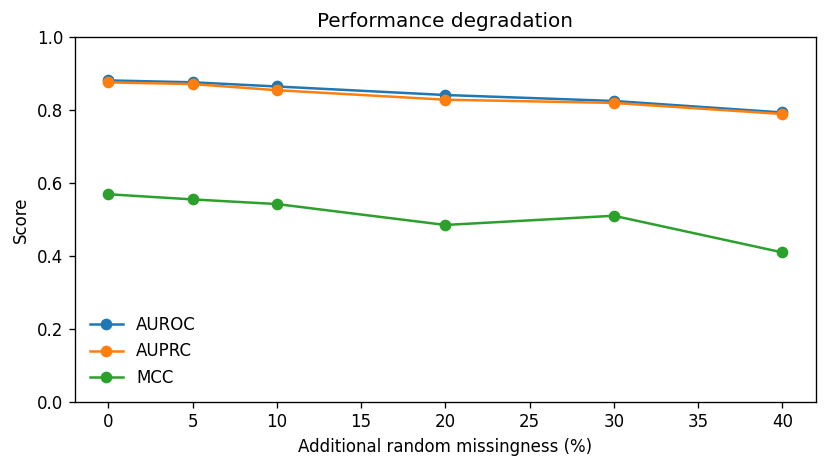

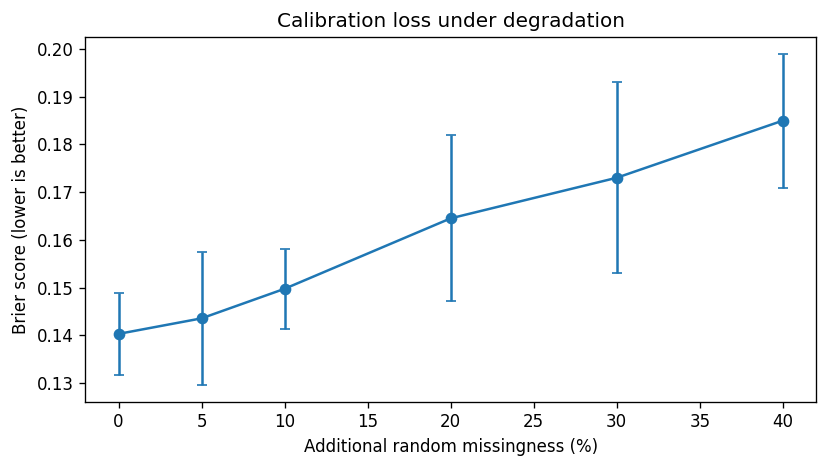

In [16]:
fig,ax=plt.subplots(figsize=(7,4))
for metric in ['AUROC','AUPRC','MCC']:
    g=deg_df.groupby('MissingFrac')[metric].mean(); ax.plot(100*g.index,g.values,'o-',label=metric)
ax.set_xlabel('Additional random missingness (%)'); ax.set_ylabel('Score'); ax.set_ylim(0,1)
ax.set_title('Performance degradation'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig10_random_degradation_performance.png',dpi=300); plt.show()

fig,ax=plt.subplots(figsize=(7,4))
g=deg_df.groupby('MissingFrac')['Brier'].agg(['mean','std']); ax.errorbar(100*g.index,g['mean'],yerr=g['std'],marker='o',capsize=3)
ax.set_xlabel('Additional random missingness (%)'); ax.set_ylabel('Brier score (lower is better)'); ax.set_title('Calibration loss under degradation')
plt.tight_layout(); plt.savefig(OUT/'fig11_random_degradation_brier.png',dpi=300); plt.show()

## 11. Clinically structured domain dropout
These scenarios emulate unavailable classes of information rather than arbitrary column deletion.


AUROC         AUPRC         Brier         \
                                mean    std   mean    std   mean    std   
Scenario                                                                  
All_tests_except_demographics  0.719  0.050  0.674  0.047  0.225  0.016   
Cardiometabolic                0.885  0.014  0.878  0.030  0.142  0.008   
ECG_exercise                   0.832  0.037  0.806  0.047  0.184  0.015   
None                           0.881  0.016  0.875  0.032  0.140  0.009   
Symptoms                       0.847  0.037  0.840  0.049  0.180  0.017   

                                 MCC         
                                mean    std  
Scenario                                     
All_tests_except_demographics  0.279  0.119  
Cardiometabolic                0.570  0.082  
ECG_exercise                   0.481  0.113  
None                           0.569  0.041  
Symptoms                       0.482  0.072

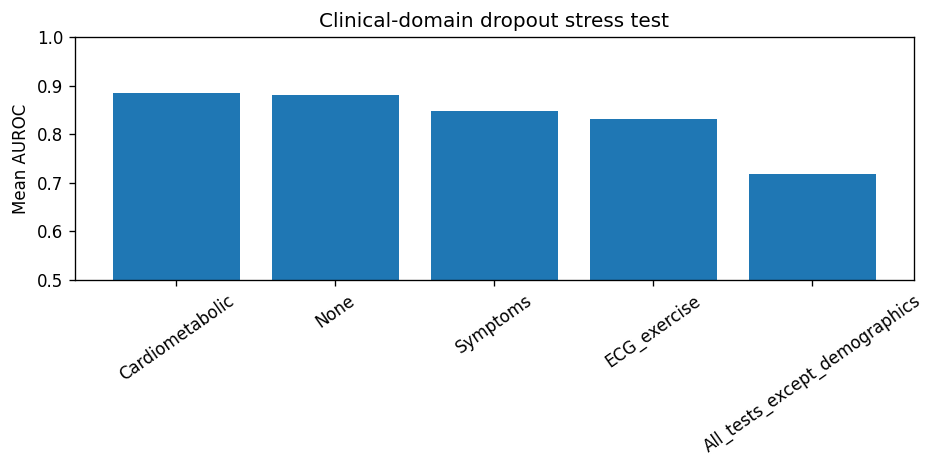

In [17]:
DOMAINS = {
    'None': [],
    'Cardiometabolic': ['trestbps','chol','fbs'],
    'ECG_exercise': ['restecg','thalach','exang','oldpeak'],
    'Symptoms': ['cp'],
    'All_tests_except_demographics': ['cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak']
}

def cv_domain_dropout(model_template,X,y,features):
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED); rows=[]
    for fold,(tr,te) in enumerate(cv.split(X,y),1):
        est=clone(model_template); est.fit(X.iloc[tr][features],y.iloc[tr])
        for name,cols in DOMAINS.items():
            z=X.iloc[te][features].copy(); z[[c for c in cols if c in z.columns]]=np.nan
            p=est.predict_proba(z)[:,1]; m=binary_metrics(y.iloc[te],p); m.update({'Fold':fold,'Scenario':name}); rows.append(m)
    return pd.DataFrame(rows)

domain_df=cv_domain_dropout(cal_template,cleveland[CORE_10],cleveland.target,CORE_10)
display(domain_df.groupby('Scenario')[['AUROC','AUPRC','Brier','MCC']].agg(['mean','std']).round(3))

fig,ax=plt.subplots(figsize=(8,4))
g=domain_df.groupby('Scenario')['AUROC'].mean().sort_values(ascending=False); ax.bar(g.index,g.values)
ax.set_ylim(.5,1); ax.set_ylabel('Mean AUROC'); ax.set_title('Clinical-domain dropout stress test'); ax.tick_params(axis='x',rotation=35)
plt.tight_layout(); plt.savefig(OUT/'fig12_domain_dropout.png',dpi=300); plt.show()

## 12. SAFE-PRED reliability score
SAFE-PRED combines three signals:
1. **calibrated confidence**: `2 × |p−0.5|`,
2. **record completeness**,
3. **in-distribution score** from an Isolation Forest fitted only on Cleveland transformed features.

Weights are pre-specified (0.50 / 0.25 / 0.25) to avoid tuning to Hungarian outcomes. The accept/defer threshold is chosen only from Cleveland development predictions.


In [18]:
# Fit a separate preprocessing transform on Cleveland only for the unsupervised OOD score.
pre_ood=make_preprocessor(CORE_10)
Zc=pre_ood.fit_transform(cleveland[CORE_10])
iso=IsolationForest(n_estimators=500, contamination='auto', random_state=SEED)
iso.fit(Zc)
raw_train=iso.score_samples(Zc)
lo,hi=np.quantile(raw_train,[.05,.95])

def id_score(raw):
    return np.clip((raw-lo)/(hi-lo+1e-12),0,1)

def completeness(X):
    return 1-X.isna().mean(axis=1).to_numpy()

def safe_score(p, X, raw_ood):
    conf=2*np.abs(np.asarray(p)-.5)
    comp=completeness(X)
    ids=id_score(raw_ood)
    return .50*conf + .25*comp + .25*ids

# Development OOF OOD scores (cross-fitted to avoid each patient's features fitting its own detector).
def crossfit_ood(X,features):
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    scores=np.full(len(X),np.nan)
    for fold,(tr,te) in enumerate(cv.split(X,cleveland.target),1):
        pre=make_preprocessor(features); Ztr=pre.fit_transform(X.iloc[tr][features]); Zte=pre.transform(X.iloc[te][features])
        m=IsolationForest(n_estimators=300,random_state=SEED+fold).fit(Ztr)
        rtr=m.score_samples(Ztr); rte=m.score_samples(Zte); qlo,qhi=np.quantile(rtr,[.05,.95])
        scores[te]=np.clip((rte-qlo)/(qhi-qlo+1e-12),0,1)
    return scores

id_oof=crossfit_ood(cleveland[CORE_10],CORE_10)
conf_oof=2*np.abs(p_oof10-.5); comp_oof=completeness(cleveland[CORE_10])
safe_oof=.50*conf_oof+.25*comp_oof+.25*id_oof

## 13. Learn a development-only deferral threshold and plot risk–coverage curves
Primary target: choose the **highest coverage** threshold that keeps selective error ≤ 10% on Cleveland OOF development predictions. If 10% is unattainable, the notebook falls back to the threshold with minimum selective error while retaining at least 30% coverage.


SAFE-PRED threshold learned from Cleveland only: 0.652


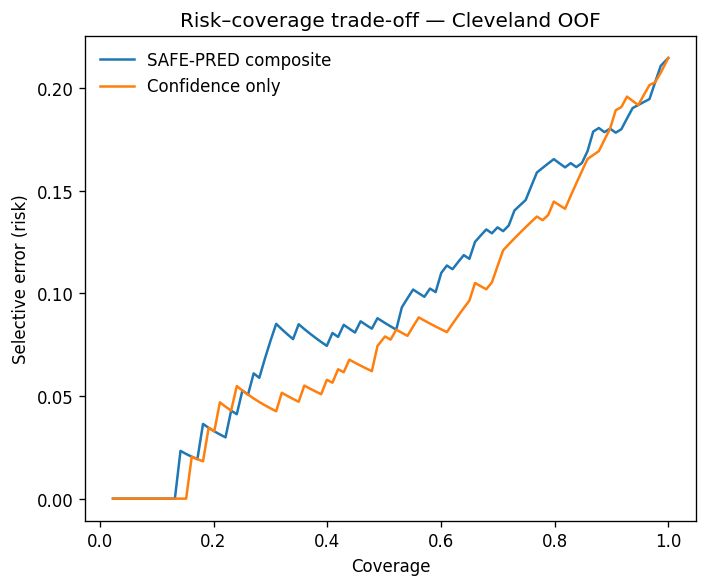

In [19]:
def risk_coverage(y,p,reliability,grid=101):
    rows=[]
    for q in np.linspace(0,1,grid):
        t=np.quantile(reliability,q)
        keep=reliability>=t
        if keep.sum()<5: continue
        pred=(p[keep]>=.5).astype(int)
        err=1-accuracy_score(np.asarray(y)[keep],pred)
        rows.append({'threshold':t,'coverage':keep.mean(),'risk':err,'n':keep.sum(),'quantile':q})
    return pd.DataFrame(rows)

rc_safe=risk_coverage(cleveland.target.to_numpy(),p_oof10,safe_oof)
rc_conf=risk_coverage(cleveland.target.to_numpy(),p_oof10,conf_oof)
feasible=rc_safe[(rc_safe.risk<=.10)&(rc_safe.coverage>=.30)]
if len(feasible):
    SAFE_THRESHOLD=feasible.sort_values('coverage',ascending=False).iloc[0].threshold
else:
    SAFE_THRESHOLD=rc_safe[rc_safe.coverage>=.30].sort_values(['risk','coverage'],ascending=[True,False]).iloc[0].threshold
print('SAFE-PRED threshold learned from Cleveland only:', round(float(SAFE_THRESHOLD),4))

fig,ax=plt.subplots(figsize=(6,5)); ax.plot(rc_safe.coverage,rc_safe.risk,label='SAFE-PRED composite'); ax.plot(rc_conf.coverage,rc_conf.risk,label='Confidence only')
ax.set_xlabel('Coverage'); ax.set_ylabel('Selective error (risk)'); ax.set_title('Risk–coverage trade-off — Cleveland OOF'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig13_risk_coverage_development.png',dpi=300); plt.show()

### Figure 14 — reliability separation for correct vs incorrect predictions


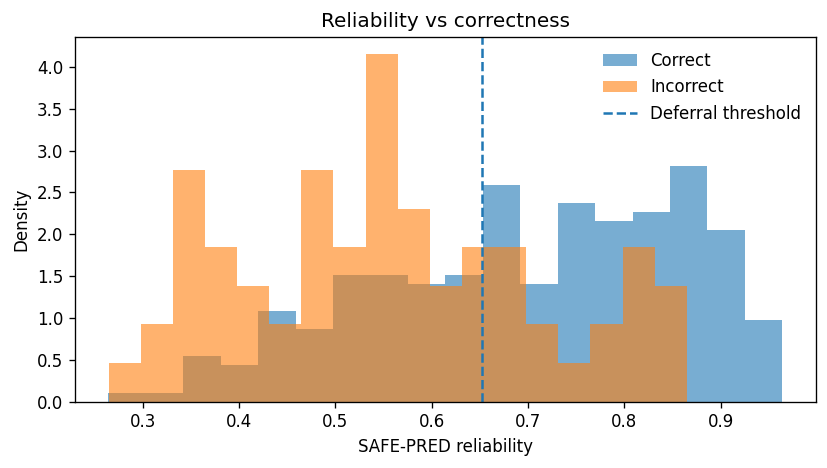

In [20]:
correct=((p_oof10>=.5).astype(int)==cleveland.target.to_numpy())
fig,ax=plt.subplots(figsize=(7,4))
ax.hist(safe_oof[correct],bins=18,alpha=.6,density=True,label='Correct')
ax.hist(safe_oof[~correct],bins=18,alpha=.6,density=True,label='Incorrect')
ax.axvline(SAFE_THRESHOLD,linestyle='--',label='Deferral threshold')
ax.set_xlabel('SAFE-PRED reliability'); ax.set_ylabel('Density'); ax.set_title('Reliability vs correctness')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(OUT/'fig14_reliability_correctness.png',dpi=300); plt.show()

## 14. Final cross-center validation on Hungarian
**No Hungarian labels were used for model selection, calibration, OOD fitting, reliability weights or deferral threshold.**


In [21]:
Xh=hungarian[CORE_10].copy(); yh=hungarian.target.to_numpy()
p_h=calibrated10.predict_proba(Xh)[:,1]
Zh=pre_ood.transform(Xh); raw_h=iso.score_samples(Zh)
safe_h=safe_score(p_h,Xh,raw_h)
accept_h=safe_h>=SAFE_THRESHOLD

external_all=binary_metrics(yh,p_h)
external_sel=binary_metrics(yh[accept_h],p_h[accept_h]) if accept_h.sum()>=5 else {}
print('Hungarian ALL cases')
display(pd.Series(external_all).round(3))
print('Hungarian ACCEPTED cases')
display(pd.Series(external_sel).round(3))
print('Coverage:', round(accept_h.mean(),3), 'Deferred:', int((~accept_h).sum()), 'of',len(yh))

pd.DataFrame({'y':yh,'p':p_h,'safe_score':safe_h,'accepted':accept_h}).to_csv(OUT/'hungarian_patient_predictions.csv',index=False)

Hungarian ALL cases


AUROC          0.879
AUPRC          0.838
BalancedAcc    0.812
Sensitivity    0.774
Specificity    0.851
MCC            0.620
Brier          0.131
dtype: float64

Hungarian ACCEPTED cases


AUROC          0.923
AUPRC          0.907
BalancedAcc    0.917
Sensitivity    0.877
Specificity    0.957
MCC            0.842
Brier          0.072
dtype: float64

Coverage: 0.612 Deferred: 114 of 294


### Figures 15–17 — external ROC, PR, calibration and risk–coverage


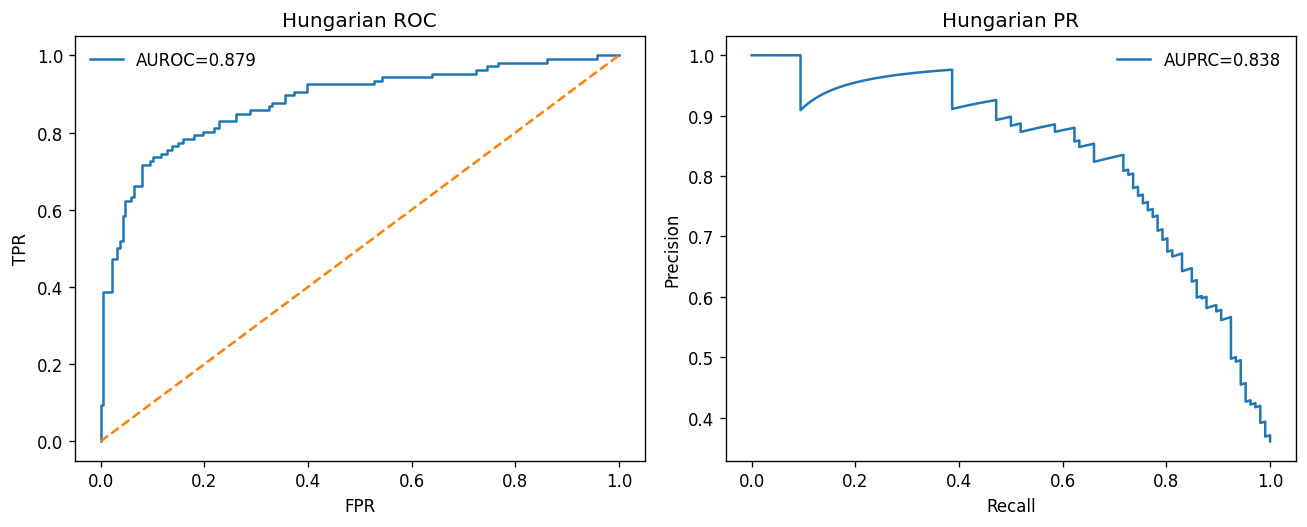

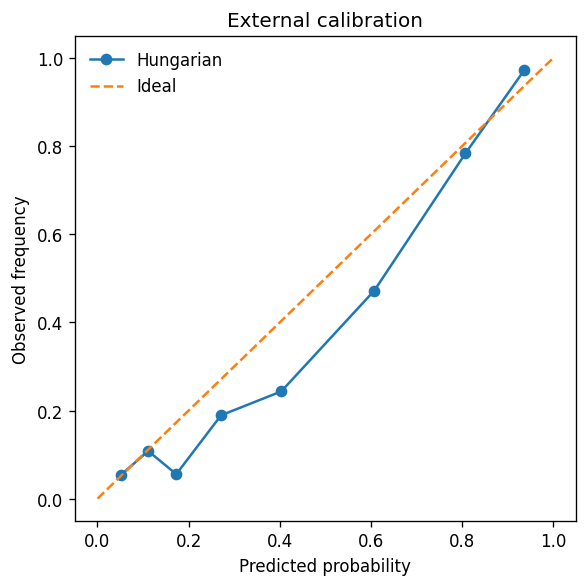

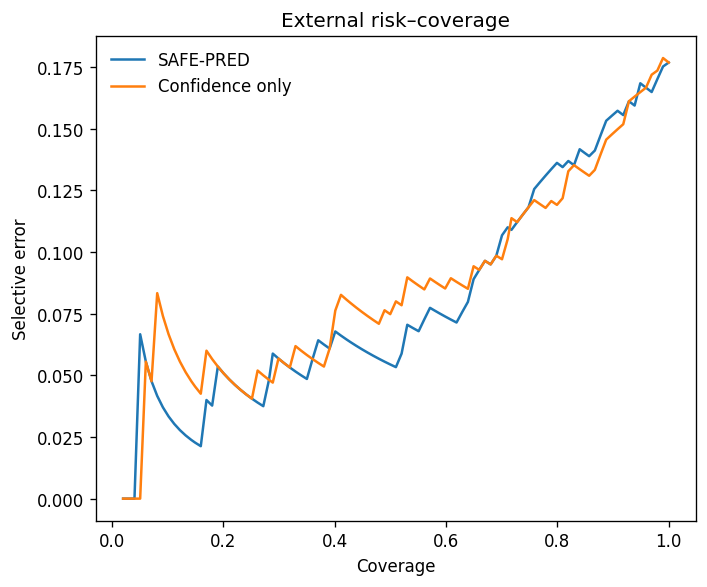

In [22]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
fpr,tpr,_=roc_curve(yh,p_h); axes[0].plot(fpr,tpr,label=f'AUROC={roc_auc_score(yh,p_h):.3f}'); axes[0].plot([0,1],[0,1],'--'); axes[0].set(xlabel='FPR',ylabel='TPR',title='Hungarian ROC'); axes[0].legend(frameon=False)
pr,rc,_=precision_recall_curve(yh,p_h); axes[1].plot(rc,pr,label=f'AUPRC={average_precision_score(yh,p_h):.3f}'); axes[1].set(xlabel='Recall',ylabel='Precision',title='Hungarian PR'); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig15_external_roc_pr.png',dpi=300); plt.show()

pt,pp=calibration_curve(yh,p_h,n_bins=8,strategy='quantile'); fig,ax=plt.subplots(figsize=(5,5)); ax.plot(pp,pt,'o-',label='Hungarian'); ax.plot([0,1],[0,1],'--',label='Ideal'); ax.set(xlabel='Predicted probability',ylabel='Observed frequency',title='External calibration'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig16_external_calibration.png',dpi=300); plt.show()

rc_ext_safe=risk_coverage(yh,p_h,safe_h); conf_h=2*np.abs(p_h-.5); rc_ext_conf=risk_coverage(yh,p_h,conf_h)
fig,ax=plt.subplots(figsize=(6,5)); ax.plot(rc_ext_safe.coverage,rc_ext_safe.risk,label='SAFE-PRED'); ax.plot(rc_ext_conf.coverage,rc_ext_conf.risk,label='Confidence only'); ax.set(xlabel='Coverage',ylabel='Selective error',title='External risk–coverage'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig17_external_risk_coverage.png',dpi=300); plt.show()

## 15. Fairness audit of deferral and error
The fairness analysis is descriptive because subgroup sizes are small. We audit **sex** and broad **age groups**. We do not claim causal fairness or clinical equity from these historical datasets.


In [23]:
def fairness_table(df,y,p,accepted,group_col,min_n=20):
    rows=[]
    for g,idx in df.groupby(group_col).groups.items():
        idx=np.asarray(list(idx),dtype=int); n=len(idx)
        if n<min_n: continue
        yy=np.asarray(y)[idx]; pp=np.asarray(p)[idx]; aa=np.asarray(accepted)[idx]
        row={'group':g,'n':n,'coverage':aa.mean(),'defer_rate':1-aa.mean(),'AUROC':np.nan,'sensitivity':np.nan,'specificity':np.nan,'selective_error':np.nan}
        if len(np.unique(yy))==2: row['AUROC']=roc_auc_score(yy,pp)
        pred=(pp>=.5).astype(int); tn,fp,fn,tp=confusion_matrix(yy,pred,labels=[0,1]).ravel(); row['sensitivity']=tp/(tp+fn) if tp+fn else np.nan; row['specificity']=tn/(tn+fp) if tn+fp else np.nan
        if aa.sum()>=5: row['selective_error']=1-accuracy_score(yy[aa],pred[aa])
        rows.append(row)
    return pd.DataFrame(rows)

hf=hungarian.reset_index(drop=True).copy(); hf['sex_group']=hf.sex.map({0.0:'Female',1.0:'Male'}).fillna('Unknown')
hf['age_group']=pd.cut(hf.age,bins=[0,54,64,np.inf],labels=['<55','55–64','65+'])
fair_sex=fairness_table(hf,yh,p_h,accept_h,'sex_group'); fair_age=fairness_table(hf,yh,p_h,accept_h,'age_group')
print('Fairness by sex'); display(fair_sex.round(3)); print('Fairness by age'); display(fair_age.round(3))
fair_sex.to_csv(OUT/'table_fairness_sex.csv',index=False); fair_age.to_csv(OUT/'table_fairness_age.csv',index=False)

Fairness by sex


,group,n,coverage,defer_rate,AUROC,sensitivity,specificity,selective_error
0,Female,81,0.704,0.296,0.798,0.500,0.942,0.070
1,Male,213,0.577,0.423,0.878,0.809,0.798,0.073


Fairness by age


,group,n,coverage,defer_rate,AUROC,sensitivity,specificity,selective_error
0,<55,236,0.636,0.364,0.882,0.738,0.885,0.060
1,55–64,54,0.481,0.519,0.842,0.864,0.688,0.154


### Figures 18–19 — coverage/deferral fairness and subgroup error


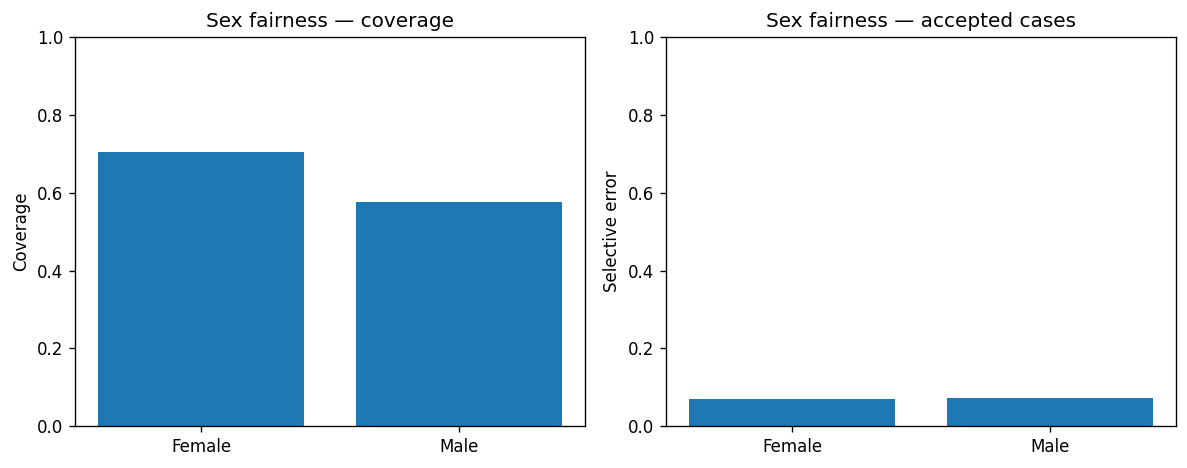

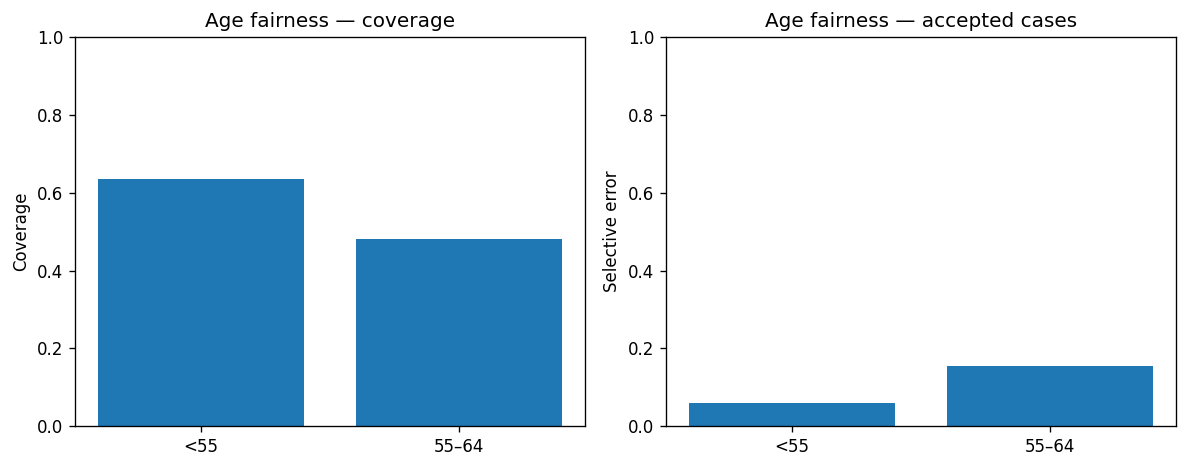

In [24]:
def fairness_plot(tab,title,filename):
    if tab.empty: return
    x=np.arange(len(tab)); fig,axes=plt.subplots(1,2,figsize=(10,4))
    axes[0].bar(x,tab.coverage); axes[0].set_xticks(x); axes[0].set_xticklabels(tab.group); axes[0].set_ylim(0,1); axes[0].set_ylabel('Coverage'); axes[0].set_title(title+' — coverage')
    axes[1].bar(x,tab.selective_error); axes[1].set_xticks(x); axes[1].set_xticklabels(tab.group); axes[1].set_ylim(0,1); axes[1].set_ylabel('Selective error'); axes[1].set_title(title+' — accepted cases')
    plt.tight_layout(); plt.savefig(OUT/filename,dpi=300); plt.show()

fairness_plot(fair_sex,'Sex fairness','fig18_fairness_sex.png')
fairness_plot(fair_age,'Age fairness','fig19_fairness_age.png')

## 16. Additional missingness stress test on Hungarian
This evaluates how the already shifted cohort behaves under further controlled data loss.


,AUROC,AUPRC,BalancedAcc,Sensitivity,Specificity,MCC,Brier,MissingFrac,Coverage,SelectiveError
0,0.879,0.838,0.812,0.774,0.851,0.620,0.131,0.00,0.612,0.072
1,0.870,0.821,0.807,0.774,0.840,0.607,0.138,0.05,0.582,0.076
2,0.868,0.822,0.793,0.745,0.840,0.582,0.141,0.10,0.524,0.078
3,0.865,0.819,0.768,0.755,0.782,0.524,0.149,0.20,0.439,0.078
4,0.860,0.802,0.763,0.792,0.734,0.508,0.158,0.30,0.364,0.065
5,0.831,0.751,0.742,0.792,0.691,0.465,0.177,0.40,0.255,0.080


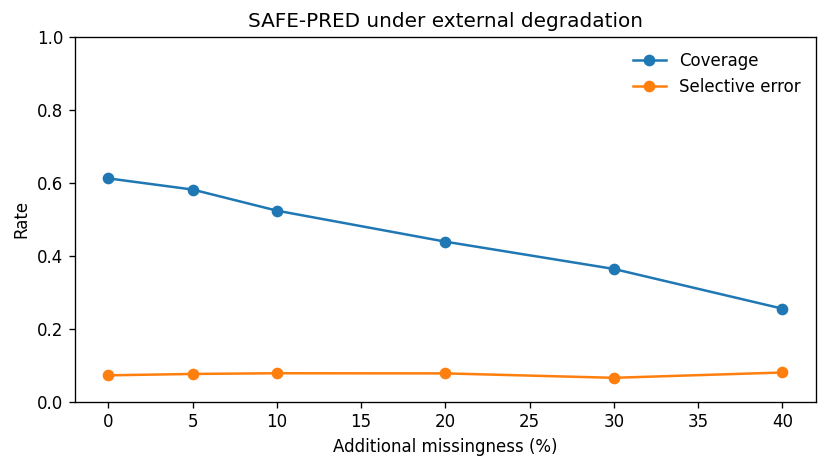

In [25]:
rows=[]
for frac in [0,.05,.10,.20,.30,.40]:
    z=degrade_random(Xh,frac,SEED+int(frac*1000)); p=calibrated10.predict_proba(z)[:,1]
    rz=iso.score_samples(pre_ood.transform(z)); s=safe_score(p,z,rz); a=s>=SAFE_THRESHOLD
    m=binary_metrics(yh,p); m.update({'MissingFrac':frac,'Coverage':a.mean(),'SelectiveError':(1-accuracy_score(yh[a],(p[a]>=.5).astype(int))) if a.sum()>=5 else np.nan}); rows.append(m)
ext_deg=pd.DataFrame(rows); display(ext_deg.round(3)); ext_deg.to_csv(OUT/'table_external_degradation.csv',index=False)

fig,ax=plt.subplots(figsize=(7,4)); ax.plot(100*ext_deg.MissingFrac,ext_deg.Coverage,'o-',label='Coverage'); ax.plot(100*ext_deg.MissingFrac,ext_deg.SelectiveError,'o-',label='Selective error'); ax.set(xlabel='Additional missingness (%)',ylabel='Rate',title='SAFE-PRED under external degradation'); ax.set_ylim(0,1); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig20_external_degradation.png',dpi=300); plt.show()

## 17. Explanation stability using permutation importance
Permutation importance is evaluated on Hungarian labels **without retraining** the Cleveland model. We compare clean Hungarian core-10 data with an additional 20% missingness condition and quantify rank stability using Spearman correlation.


Permutation-importance rank stability, Spearman rho= 0.915 p= 0.0002


,clean,degraded20
age,-0.0006,0.0023
chol,0.0074,0.0090
cp,0.0562,0.0589
exang,0.0169,0.0166
fbs,-0.0001,0.0001
oldpeak,0.0375,0.0413
restecg,-0.0004,0.0004
sex,0.0326,0.0331
thalach,0.0069,0.0269
trestbps,-0.0016,-0.0010


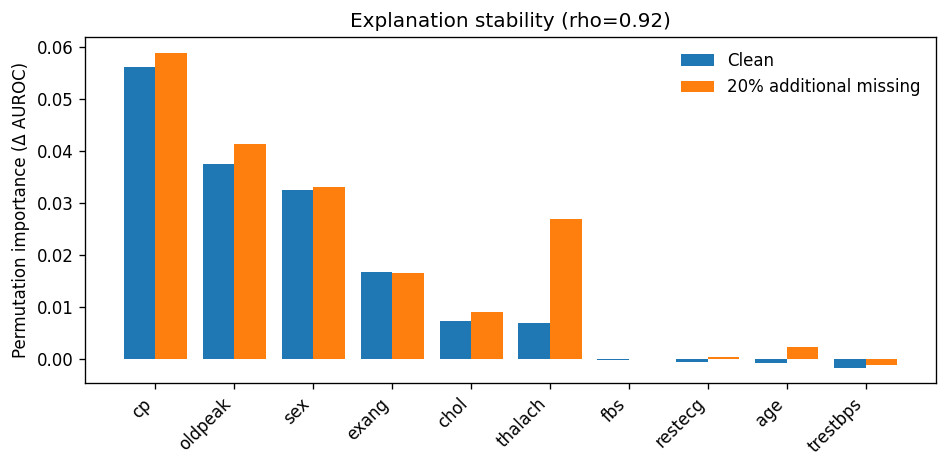

In [26]:
def perm_imp_on(model,X,y,seed=SEED):
    r=permutation_importance(model,X,y,n_repeats=40,random_state=seed,scoring='roc_auc',n_jobs=-1)
    return pd.Series(r.importances_mean,index=X.columns).sort_values(ascending=False)

imp_clean=perm_imp_on(calibrated10,Xh,yh)
Xh20=degrade_random(Xh,.20,SEED+2026)
imp_deg=perm_imp_on(calibrated10,Xh20,yh,SEED+1)
imp=pd.DataFrame({'clean':imp_clean,'degraded20':imp_deg}).fillna(0)
rho,pval=spearmanr(imp['clean'],imp['degraded20'])
print('Permutation-importance rank stability, Spearman rho=',round(float(rho),3),'p=',round(float(pval),4))
display(imp.round(4))

fig,ax=plt.subplots(figsize=(8,4)); order=imp.clean.sort_values(ascending=False).index; x=np.arange(len(order)); w=.4
ax.bar(x-w/2,imp.loc[order,'clean'],width=w,label='Clean'); ax.bar(x+w/2,imp.loc[order,'degraded20'],width=w,label='20% additional missing')
ax.set_xticks(x); ax.set_xticklabels(order,rotation=45,ha='right'); ax.set_ylabel('Permutation importance (Δ AUROC)'); ax.set_title(f'Explanation stability (rho={rho:.2f})'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig21_explanation_stability.png',dpi=300); plt.show()

## 18. Bootstrap confidence intervals for key external results
Patient-level nonparametric bootstrap is used for uncertainty. These intervals reflect sampling variability in this cohort; they do not make the historical cohort representative of current practice.


In [27]:
def bootstrap_metric(y,p,accepted=None,B=2000,seed=SEED):
    rng=np.random.default_rng(seed); n=len(y); vals=[]
    for _ in range(B):
        idx=rng.integers(0,n,n); yy=np.asarray(y)[idx]; pp=np.asarray(p)[idx]
        if len(np.unique(yy))<2: continue
        if accepted is None:
            vals.append(roc_auc_score(yy,pp))
        else:
            aa=np.asarray(accepted)[idx]
            if aa.sum()<5: continue
            vals.append(1-accuracy_score(yy[aa],(pp[aa]>=.5).astype(int)))
    return np.quantile(vals,[.025,.5,.975])

auc_ci=bootstrap_metric(yh,p_h)
risk_ci=bootstrap_metric(yh,p_h,accept_h)
ci_table=pd.DataFrame({
    'Metric':['External AUROC','Selective error among accepted'],
    '2.5%':[auc_ci[0],risk_ci[0]],'Median':[auc_ci[1],risk_ci[1]],'97.5%':[auc_ci[2],risk_ci[2]]
})
display(ci_table.round(3)); ci_table.to_csv(OUT/'table_bootstrap_ci.csv',index=False)

,Metric,2.5%,Median,97.5%
0,External AUROC,0.836,0.880,0.919
1,Selective error among accepted,0.035,0.071,0.111


## 19. Sensitivity analysis: full-13 transfer to Hungarian
Because `slope`, `ca`, and `thal` are extremely sparse in Hungarian, the primary cross-center result uses core-10. This sensitivity analysis quantifies what happens when all 13 features are retained and training-fold imputation is relied upon.


In [28]:
sel13,best_name13,best13 = choose_model_on_development(cleveland,cleveland.target,FEATURES_13)
cal13=CalibratedClassifierCV(estimator=clone(best13),method='sigmoid',cv=5).fit(cleveland[FEATURES_13],cleveland.target)
p13=cal13.predict_proba(hungarian[FEATURES_13])[:,1]
full13_ext=pd.Series(binary_metrics(yh,p13),name='Full13_Hungarian')
core10_ext=pd.Series(binary_metrics(yh,p_h),name='Core10_Hungarian')
compare_ext=pd.concat([core10_ext,full13_ext],axis=1)
display(compare_ext.round(3)); compare_ext.to_csv(OUT/'table_core10_vs_full13_external.csv')

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

,Core10_Hungarian,Full13_Hungarian
AUROC,0.879,0.896
AUPRC,0.838,0.850
BalancedAcc,0.812,0.754
Sensitivity,0.774,0.566
Specificity,0.851,0.941
MCC,0.620,0.569
Brier,0.131,0.133


## 20. Upgrade utilities: selective prediction, AURC/E-AURC, matched coverage

Lower AURC/E-AURC means the reliability score ranks error-prone cases later, allowing safer automation at a given coverage.


In [29]:
def classification_error(y,p,threshold=0.5):
    y=np.asarray(y); p=np.asarray(p)
    return np.mean((p>=threshold).astype(int)!=y)

def reliability_order_metrics(y,p,score):
    y=np.asarray(y); p=np.asarray(p); score=np.asarray(score)
    err=((p>=0.5).astype(int)!=y).astype(float)
    order=np.argsort(-score)
    e=err[order]
    cov=np.arange(1,len(e)+1)/len(e)
    risk=np.cumsum(e)/np.arange(1,len(e)+1)
    aurc=float(np.trapz(risk,cov))
    oracle_e=np.sort(err)
    oracle_risk=np.cumsum(oracle_e)/np.arange(1,len(oracle_e)+1)
    oracle=float(np.trapz(oracle_risk,cov))
    return {'AURC':aurc,'Oracle_AURC':oracle,'E_AURC':aurc-oracle}

def metrics_at_coverage(y,p,score,coverage):
    y=np.asarray(y); p=np.asarray(p); score=np.asarray(score)
    k=max(5,int(np.floor(len(y)*coverage)))
    idx=np.argsort(-score)[:k]
    yy,pp=y[idx],p[idx]
    pred=(pp>=0.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(yy,pred,labels=[0,1]).ravel()
    return {
        'coverage_target':coverage,'actual_coverage':k/len(y),'n':k,
        'selective_error':classification_error(yy,pp),
        'AUROC':roc_auc_score(yy,pp) if len(np.unique(yy))==2 else np.nan,
        'AUPRC':average_precision_score(yy,pp) if len(np.unique(yy))==2 else np.nan,
        'Brier':brier_score_loss(yy,pp),
        'Sensitivity':tp/(tp+fn) if tp+fn else np.nan,
        'Specificity':tn/(tn+fp) if tn+fp else np.nan
    }

def capture_rate_of_errors(y,p,accepted):
    y=np.asarray(y); p=np.asarray(p); accepted=np.asarray(accepted)
    err=((p>=0.5).astype(int)!=y)
    return ((~accepted)&err).sum()/err.sum() if err.sum() else np.nan

def high_confidence_error_stats(y,p,accepted=None,confidence_cut=0.90):
    y=np.asarray(y); p=np.asarray(p)
    conf=np.maximum(p,1-p); err=((p>=0.5).astype(int)!=y); hce=err&(conf>=confidence_cut)
    out={'n':len(y),'errors':int(err.sum()),'high_confidence_errors':int(hce.sum()),
         'HCE_rate_all':float(hce.mean()),
         'HCE_fraction_of_errors':float(hce.sum()/err.sum()) if err.sum() else np.nan}
    if accepted is not None:
        accepted=np.asarray(accepted)
        out['HCE_deferred_fraction']=float(((~accepted)&hce).sum()/hce.sum()) if hce.sum() else np.nan
    return out
print('Upgrade utilities loaded.')


Upgrade utilities loaded.


## 21. Single-feature ablation on Cleveland: Clinical Information Criticality

Each core feature is removed **one at a time**. Ablated predictions are cross-fitted on Cleveland. Criticality is derived only from performance damage in Cleveland, never from Hungarian outcomes.


In [30]:
reference_dev=binary_metrics(cleveland.target,p_oof10)
reference_cov=float((safe_oof>=SAFE_THRESHOLD).mean())
rows=[]
for feature in CORE_10:
    feats=[f for f in CORE_10 if f!=feature]
    pipe,grid=model_space(feats)[best_name10]
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    pab=np.full(len(cleveland),np.nan)
    for fold,(tr,te) in enumerate(cv.split(cleveland,cleveland.target),1):
        inner=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED+100+fold)
        gs=GridSearchCV(pipe,grid,scoring='roc_auc',cv=inner,n_jobs=-1,refit=True)
        gs.fit(cleveland.iloc[tr][feats],cleveland.target.iloc[tr])
        pab[te]=gs.predict_proba(cleveland.iloc[te][feats])[:,1]
    m=binary_metrics(cleveland.target,pab)
    rows.append({'Feature':feature,**m,
                 'Delta_AUROC':reference_dev['AUROC']-m['AUROC'],
                 'Delta_AUPRC':reference_dev['AUPRC']-m['AUPRC'],
                 'Delta_Brier':m['Brier']-reference_dev['Brier'],
                 'Delta_Sensitivity':reference_dev['Sensitivity']-m['Sensitivity'],
                 'Delta_BalancedAcc':reference_dev['BalancedAcc']-m['BalancedAcc']})
single_dev=pd.DataFrame(rows)
crit=pd.DataFrame({
    'auc':np.clip(single_dev.Delta_AUROC,0,None),
    'auprc':np.clip(single_dev.Delta_AUPRC,0,None),
    'brier':np.clip(single_dev.Delta_Brier,0,None),
    'sens':np.clip(single_dev.Delta_Sensitivity,0,None)
})
for c in crit.columns:
    crit[c]=crit[c]/(crit[c].max()+1e-12)
single_dev['CriticalityScore']=crit.mean(axis=1)
single_dev=single_dev.sort_values('CriticalityScore',ascending=False).reset_index(drop=True)
criticality_map=dict(zip(single_dev.Feature,single_dev.CriticalityScore))
display(single_dev.round(4))
single_dev.to_csv(OUT/'table_single_feature_ablation_development.csv',index=False)


,Feature,AUROC,AUPRC,BalancedAcc,Sensitivity,Specificity,MCC,Brier,Delta_AUROC,Delta_AUPRC,Delta_Brier,Delta_Sensitivity,Delta_BalancedAcc,CriticalityScore
0,sex,0.8428,0.8273,0.7589,0.6763,0.8415,0.5275,0.1585,0.0363,0.0397,0.0182,0.0504,0.0221,0.9631
1,cp,0.8437,0.8242,0.7655,0.6835,0.8476,0.5410,0.1599,0.0354,0.0429,0.0196,0.0432,0.0155,0.9576
2,oldpeak,0.8645,0.8385,0.7749,0.7266,0.8232,0.5535,0.1484,0.0146,0.0286,0.0081,0.0000,0.0061,0.3698
3,thalach,0.8677,0.8459,0.7851,0.7410,0.8293,0.5736,0.1453,0.0114,0.0212,0.0050,-0.0144,-0.0041,0.2653
4,exang,0.8749,0.8547,0.7732,0.7050,0.8415,0.5538,0.1433,0.0042,0.0123,0.0029,0.0216,0.0077,0.2453
5,age,0.8729,0.8572,0.7804,0.7194,0.8415,0.5671,0.1429,0.0062,0.0098,0.0026,0.0072,0.0005,0.1683
6,chol,0.8784,0.8553,0.7799,0.7122,0.8476,0.5673,0.1406,0.0007,0.0118,0.0003,0.0144,0.0011,0.1485
7,trestbps,0.8751,0.8596,0.7846,0.7338,0.8354,0.5736,0.1420,0.0040,0.0075,0.0017,-0.0072,-0.0036,0.0925
8,fbs,0.8792,0.8635,0.7937,0.7338,0.8537,0.5939,0.1391,-0.0001,0.0036,-0.0012,-0.0072,-0.0127,0.0209
9,restecg,0.8790,0.8686,0.7779,0.7266,0.8293,0.5602,0.1408,0.0001,-0.0015,0.0004,0.0000,0.0030,0.0063


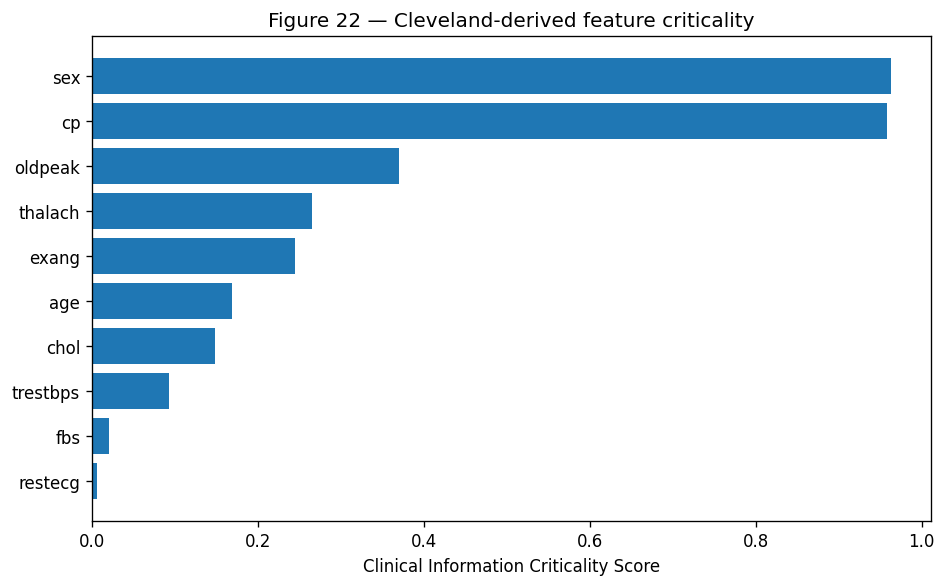

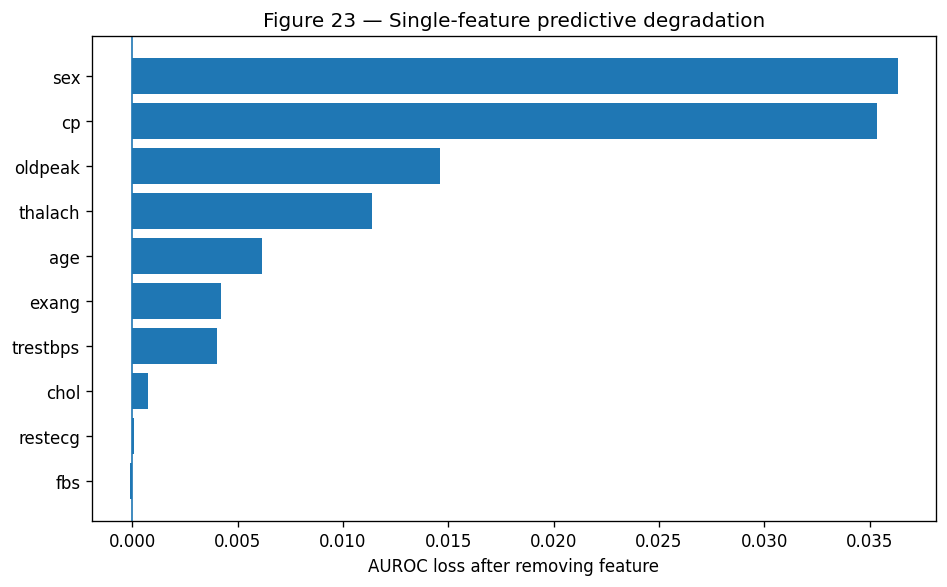

In [31]:
fig,ax=plt.subplots(figsize=(8,5))
g=single_dev.sort_values('CriticalityScore')
ax.barh(g.Feature,g.CriticalityScore)
ax.set_xlabel('Clinical Information Criticality Score')
ax.set_title('Figure 22 — Cleveland-derived feature criticality')
plt.tight_layout(); plt.savefig(OUT/'fig22_feature_criticality_development.png',dpi=300); plt.show()

fig,ax=plt.subplots(figsize=(8,5))
g=single_dev.sort_values('Delta_AUROC')
ax.barh(g.Feature,g.Delta_AUROC); ax.axvline(0,linewidth=1)
ax.set_xlabel('AUROC loss after removing feature')
ax.set_title('Figure 23 — Single-feature predictive degradation')
plt.tight_layout(); plt.savefig(OUT/'fig23_single_feature_delta_auroc.png',dpi=300); plt.show()


## 22. External single-feature ablation and criticality transfer

The Cleveland-derived criticality map is frozen. Each Hungarian feature is then removed individually to test whether development criticality predicts external vulnerability.


,Feature,AUROC,AUPRC,BalancedAcc,Sensitivity,Specificity,MCC,Brier,Delta_AUROC,Delta_AUPRC,Delta_Brier,Delta_Sensitivity,Coverage_SAFE,SelectiveError_SAFE,DevelopmentCriticality
1,sex,0.8667,0.8137,0.8005,0.7925,0.8085,0.5871,0.1484,0.0126,0.0243,0.0173,-0.0189,0.5068,0.1007,0.9631
2,cp,0.8537,0.8142,0.7511,0.8585,0.6436,0.4835,0.1863,0.0256,0.0238,0.0552,-0.0849,0.3333,0.0918,0.9576
9,oldpeak,0.8551,0.8005,0.7878,0.7830,0.7926,0.5609,0.1497,0.0242,0.0375,0.0186,-0.0094,0.5068,0.0872,0.3698
7,thalach,0.8829,0.8411,0.8065,0.6981,0.9149,0.6386,0.1259,-0.0036,-0.0031,-0.0052,0.0755,0.5680,0.0539,0.2653
8,exang,0.8688,0.8237,0.8014,0.7358,0.8670,0.6068,0.1348,0.0105,0.0143,0.0037,0.0377,0.5238,0.0909,0.2453
0,age,0.8811,0.8406,0.8031,0.7925,0.8138,0.5931,0.1337,-0.0018,-0.0027,0.0026,-0.0189,0.5578,0.0671,0.1683
4,chol,0.8736,0.8304,0.8049,0.7642,0.8457,0.6052,0.1332,0.0057,0.0075,0.0021,0.0094,0.5952,0.0800,0.1485
3,trestbps,0.8852,0.8400,0.8115,0.7453,0.8777,0.6284,0.1276,-0.0059,-0.0020,-0.0035,0.0283,0.5850,0.0640,0.0925
5,fbs,0.8795,0.8382,0.8123,0.7736,0.8511,0.6198,0.1311,-0.0002,-0.0002,0.0000,0.0000,0.5850,0.0756,0.0209
6,restecg,0.8806,0.8436,0.8197,0.7830,0.8564,0.6345,0.1304,-0.0013,-0.0056,-0.0007,-0.0094,0.5952,0.0914,0.0063


Criticality transfer rho=0.624, p=0.0537


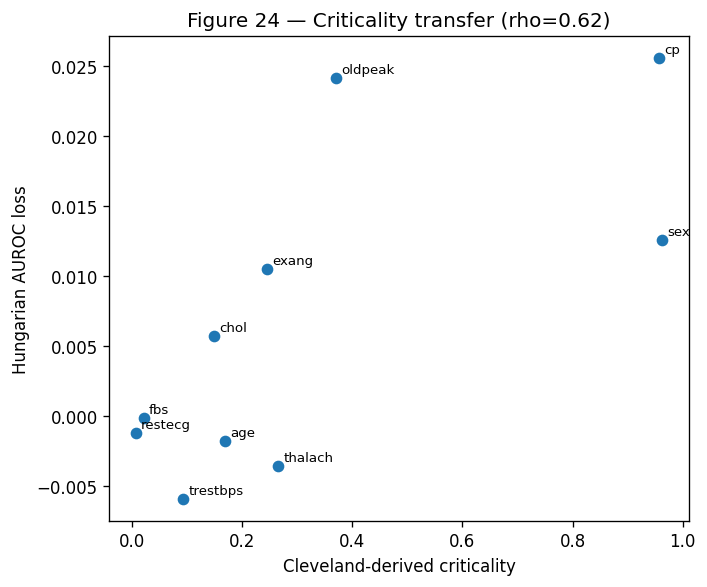

In [32]:
external_reference=binary_metrics(yh,p_h)
rows=[]
for feature in CORE_10:
    z=Xh.copy(); z[feature]=np.nan
    p=calibrated10.predict_proba(z)[:,1]
    m=binary_metrics(yh,p)
    rz=iso.score_samples(pre_ood.transform(z)); s=safe_score(p,z,rz); a=s>=SAFE_THRESHOLD
    rows.append({'Feature':feature,**m,
                 'Delta_AUROC':external_reference['AUROC']-m['AUROC'],
                 'Delta_AUPRC':external_reference['AUPRC']-m['AUPRC'],
                 'Delta_Brier':m['Brier']-external_reference['Brier'],
                 'Delta_Sensitivity':external_reference['Sensitivity']-m['Sensitivity'],
                 'Coverage_SAFE':a.mean(),
                 'SelectiveError_SAFE':classification_error(yh[a],p[a]) if a.sum()>=5 else np.nan,
                 'DevelopmentCriticality':criticality_map[feature]})
single_ext=pd.DataFrame(rows).sort_values('DevelopmentCriticality',ascending=False)
rho_crit,p_crit=spearmanr(single_ext.DevelopmentCriticality,single_ext.Delta_AUROC)
display(single_ext.round(4)); print(f'Criticality transfer rho={rho_crit:.3f}, p={p_crit:.4f}')
single_ext.to_csv(OUT/'table_single_feature_ablation_external.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5)); ax.scatter(single_ext.DevelopmentCriticality,single_ext.Delta_AUROC)
for _,r in single_ext.iterrows(): ax.annotate(r.Feature,(r.DevelopmentCriticality,r.Delta_AUROC),fontsize=8,xytext=(3,3),textcoords='offset points')
ax.set_xlabel('Cleveland-derived criticality'); ax.set_ylabel('Hungarian AUROC loss')
ax.set_title(f'Figure 24 — Criticality transfer (rho={rho_crit:.2f})')
plt.tight_layout(); plt.savefig(OUT/'fig24_criticality_transfer.png',dpi=300); plt.show()


## 23. Equal missingness, different feature criticality

High-criticality and low-criticality features are removed in equal numbers. This tests whether **which information is missing** matters beyond the percentage missing.


,Scenario,N_features_removed,Features_removed,AUROC,AUPRC,BalancedAcc,Sensitivity,Specificity,MCC,Brier,Coverage_SAFE,SelectiveError_SAFE
0,High-criticality,1,sex,0.8667,0.8137,0.8005,0.7925,0.8085,0.5871,0.1484,0.5068,0.1007
1,Low-criticality,1,restecg,0.8806,0.8436,0.8197,0.7830,0.8564,0.6345,0.1304,0.5952,0.0914
2,High-criticality,2,"sex, cp",0.8307,0.7880,0.6795,0.8962,0.4628,0.3657,0.2339,0.2789,0.1585
3,Low-criticality,2,"restecg, fbs",0.8806,0.8436,0.8197,0.7830,0.8564,0.6345,0.1304,0.5816,0.0760
4,High-criticality,3,"sex, cp, oldpeak",0.7803,0.7154,0.5799,0.9151,0.2447,0.1967,0.2767,0.2109,0.2903
5,Low-criticality,3,"restecg, fbs, trestbps",0.8856,0.8447,0.8182,0.7642,0.8723,0.6378,0.1269,0.5816,0.0643
6,High-criticality,4,"sex, cp, oldpeak, thalach",0.7674,0.7041,0.5873,0.9245,0.2500,0.2149,0.2580,0.0408,0.1667
7,Low-criticality,4,"restecg, fbs, trestbps, chol",0.8791,0.8387,0.7914,0.7264,0.8564,0.5853,0.1292,0.5510,0.0679


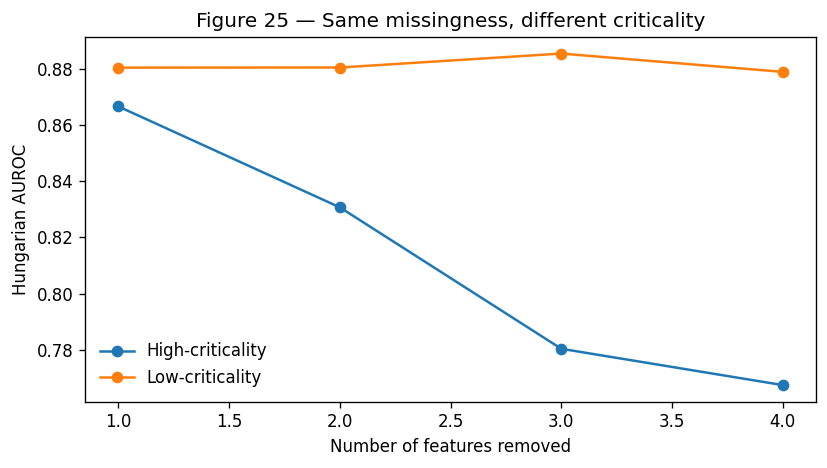

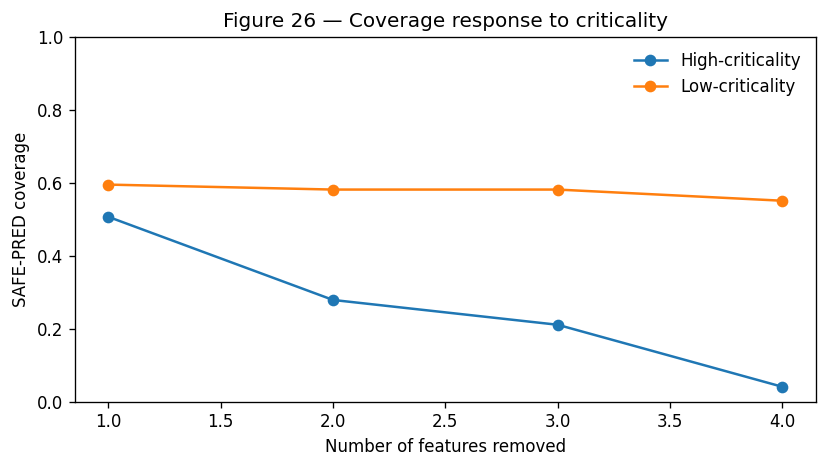

In [33]:
ranked_high=single_dev.sort_values('CriticalityScore',ascending=False).Feature.tolist()
ranked_low=list(reversed(ranked_high))
rows=[]
for k in [1,2,3,4]:
    for label,order in [('High-criticality',ranked_high),('Low-criticality',ranked_low)]:
        z=Xh.copy(); drop=order[:k]; z[drop]=np.nan
        p=calibrated10.predict_proba(z)[:,1]; rz=iso.score_samples(pre_ood.transform(z)); s=safe_score(p,z,rz); a=s>=SAFE_THRESHOLD
        m=binary_metrics(yh,p)
        rows.append({'Scenario':label,'N_features_removed':k,'Features_removed':', '.join(drop),**m,
                     'Coverage_SAFE':a.mean(),'SelectiveError_SAFE':classification_error(yh[a],p[a]) if a.sum()>=5 else np.nan})
critical_dropout=pd.DataFrame(rows); display(critical_dropout.round(4)); critical_dropout.to_csv(OUT/'table_high_vs_low_criticality_dropout.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
for s,g in critical_dropout.groupby('Scenario'): ax.plot(g.N_features_removed,g.AUROC,'o-',label=s)
ax.set_xlabel('Number of features removed'); ax.set_ylabel('Hungarian AUROC'); ax.set_title('Figure 25 — Same missingness, different criticality'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig25_high_vs_low_criticality_auroc.png',dpi=300); plt.show()
fig,ax=plt.subplots(figsize=(7,4))
for s,g in critical_dropout.groupby('Scenario'): ax.plot(g.N_features_removed,g.Coverage_SAFE,'o-',label=s)
ax.set_xlabel('Number of features removed'); ax.set_ylabel('SAFE-PRED coverage'); ax.set_ylim(0,1); ax.set_title('Figure 26 — Coverage response to criticality'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig26_high_vs_low_criticality_coverage.png',dpi=300); plt.show()


## 24. Ensemble-disagreement baseline

This baseline is not a monotonic transformation of probability confidence. Reliability is higher when independently bootstrapped Cleveland models agree.


In [34]:
def build_committee(base,X,y,features,n_members=20,seed=SEED):
    rng=np.random.default_rng(seed); out=[]
    for m in range(n_members):
        idx=rng.integers(0,len(X),len(X)); est=clone(base); est.fit(X.iloc[idx][features],y.iloc[idx]); out.append(est)
    return out

def committee_predict(members,X,features):
    P=np.column_stack([m.predict_proba(X[features])[:,1] for m in members]); return P.mean(1),P.std(1)

def crossfit_committee(base,X,y,features,n_members=10,seed=SEED):
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=seed); mean=np.full(len(y),np.nan); std=np.full(len(y),np.nan); rng=np.random.default_rng(seed+1000)
    for fold,(tr,te) in enumerate(cv.split(X,y),1):
        members=[]; Xtr=X.iloc[tr]; ytr=y.iloc[tr]
        for m in range(n_members):
            b=rng.integers(0,len(tr),len(tr)); est=clone(base); est.fit(Xtr.iloc[b][features],ytr.iloc[b]); members.append(est)
        P=np.column_stack([e.predict_proba(X.iloc[te][features])[:,1] for e in members]); mean[te]=P.mean(1); std[te]=P.std(1)
    return mean,std
committee_mean_dev,committee_std_dev=crossfit_committee(clone(best10),cleveland[CORE_10],cleveland.target,CORE_10)
q95=np.quantile(committee_std_dev,.95)+1e-12
ensemble_rel_dev=1-np.clip(committee_std_dev/q95,0,1)
committee=build_committee(clone(best10),cleveland[CORE_10],cleveland.target,CORE_10)
committee_mean_h,committee_std_h=committee_predict(committee,Xh,CORE_10)
ensemble_rel_h=1-np.clip(committee_std_h/q95,0,1)
print('Ensemble disagreement baseline ready.')


Ensemble disagreement baseline ready.


## 25. Feature-Aware SAFE-PRED

Patient-level reliability now incorporates the **criticality of missing information**, not only the amount missing. Component weights are selected on Cleveland only by minimizing AURC.


In [35]:
crit_vec=np.array([criticality_map[f] for f in CORE_10],float); crit_vec=crit_vec/(crit_vec.sum()+1e-12)
def critical_availability(X):
    return np.clip(1-(X[CORE_10].isna().to_numpy().astype(float)@crit_vec),0,1)
crit_dev=critical_availability(cleveland[CORE_10]); crit_h=critical_availability(Xh)
weights=[]
grid=[.10,.20,.30,.40,.50,.60]
for wc in grid:
    for wcomp in grid:
        for wid in grid:
            wcrit=1-wc-wcomp-wid
            if .10<=wcrit<=.60: weights.append((wc,wcomp,wid,wcrit))
rows=[]
for wc,wcomp,wid,wcrit in weights:
    s=wc*conf_oof+wcomp*comp_oof+wid*id_oof+wcrit*crit_dev
    r=reliability_order_metrics(cleveland.target,p_oof10,s); m=metrics_at_coverage(cleveland.target,p_oof10,s,.60)
    rows.append({'w_conf':wc,'w_complete':wcomp,'w_id':wid,'w_critical':wcrit,**r,'risk_at_60':m['selective_error']})
weight_search=pd.DataFrame(rows).sort_values(['AURC','risk_at_60']).reset_index(drop=True)
BEST_W=weight_search.iloc[0][['w_conf','w_complete','w_id','w_critical']].to_dict(); display(weight_search.head(10).round(4)); print('Selected weights:',BEST_W)
def feature_aware_score(p,X,raw):
    return (BEST_W['w_conf']*(2*np.abs(np.asarray(p)-.5))+
            BEST_W['w_complete']*completeness(X)+
            BEST_W['w_id']*id_score(raw)+
            BEST_W['w_critical']*critical_availability(X))
fa_oof=BEST_W['w_conf']*conf_oof+BEST_W['w_complete']*comp_oof+BEST_W['w_id']*id_oof+BEST_W['w_critical']*crit_dev
fa_h=feature_aware_score(p_h,Xh,raw_h)
rc_fa=risk_coverage(cleveland.target.to_numpy(),p_oof10,fa_oof)
feas=rc_fa[(rc_fa.risk<=.10)&(rc_fa.coverage>=.30)]
FA_THRESHOLD=(feas.sort_values('coverage',ascending=False).iloc[0].threshold if len(feas) else rc_fa[rc_fa.coverage>=.30].sort_values(['risk','coverage'],ascending=[True,False]).iloc[0].threshold)
accept_fa_h=fa_h>=FA_THRESHOLD
print('Feature-Aware threshold:',round(float(FA_THRESHOLD),4),' External coverage:',round(float(accept_fa_h.mean()),4))


,w_conf,w_complete,w_id,w_critical,AURC,Oracle_AURC,E_AURC,risk_at_60
0,0.6,0.1,0.1,0.2,0.0865,0.0249,0.0617,0.0884
1,0.6,0.2,0.1,0.1,0.0865,0.0249,0.0617,0.0884
2,0.5,0.1,0.1,0.3,0.0874,0.0249,0.0626,0.0939
3,0.5,0.2,0.1,0.2,0.0874,0.0249,0.0626,0.0939
4,0.5,0.3,0.1,0.1,0.0874,0.0249,0.0626,0.0939
5,0.4,0.1,0.1,0.4,0.0889,0.0249,0.0641,0.0939
6,0.4,0.2,0.1,0.3,0.0889,0.0249,0.0641,0.0939
7,0.4,0.3,0.1,0.2,0.0889,0.0249,0.0641,0.0939
8,0.3,0.1,0.1,0.5,0.0914,0.0249,0.0666,0.0884
9,0.3,0.2,0.1,0.4,0.0914,0.0249,0.0666,0.0884


Selected weights: {'w_conf': 0.6, 'w_complete': 0.1, 'w_id': 0.1, 'w_critical': 0.20000000000000004}
Feature-Aware threshold: 0.6056  External coverage: 0.7075


## 26. Selective-method comparison: AURC / E-AURC and risk–coverage


,Method,AURC,Oracle_AURC,E_AURC
4,SAFE-PRED,0.08010,0.01665,0.06345
5,FeatureAware_SAFE-PRED,0.08016,0.01665,0.06351
0,Confidence,0.08540,0.01665,0.06874
3,EnsembleAgreement,0.09971,0.01665,0.08306
2,OOD,0.16888,0.01665,0.15222
1,Completeness,0.28248,0.01665,0.26582


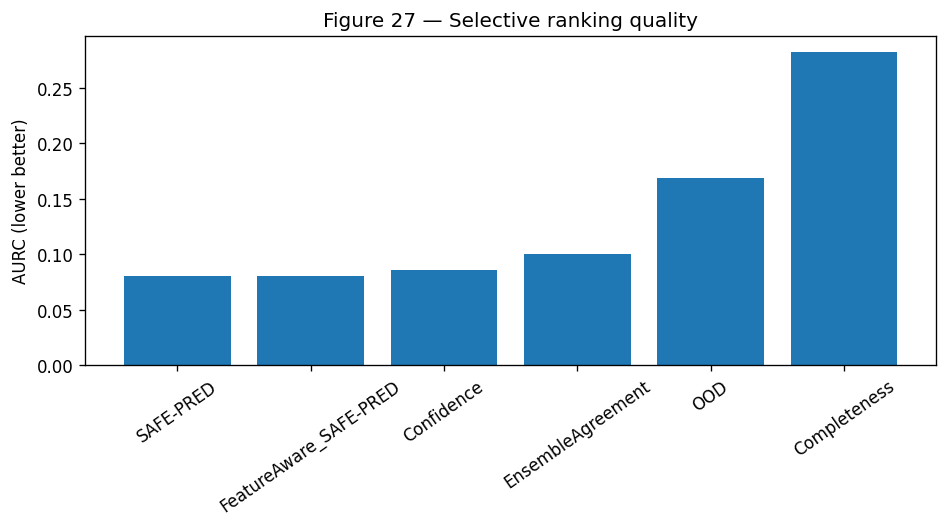

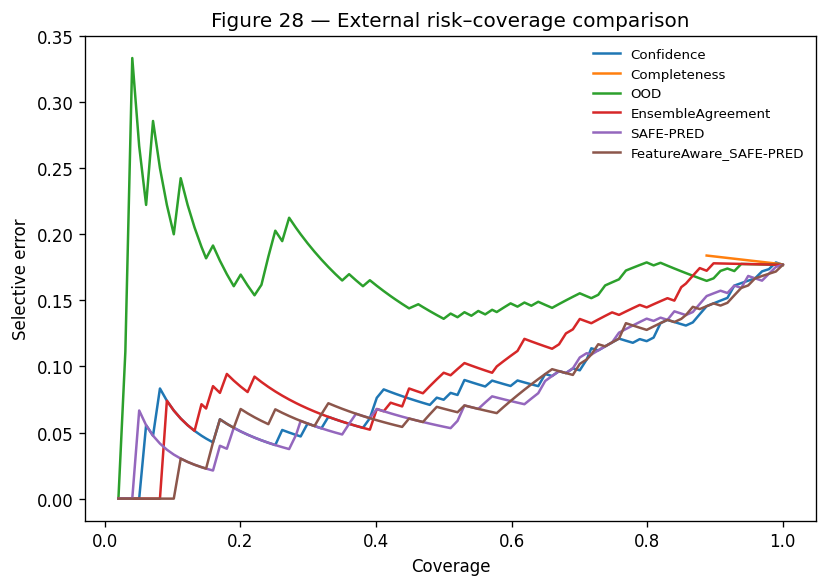

In [36]:
method_scores_dev={'Confidence':conf_oof,'Completeness':comp_oof,'OOD':id_oof,'EnsembleAgreement':ensemble_rel_dev,'SAFE-PRED':safe_oof,'FeatureAware_SAFE-PRED':fa_oof}
method_scores_h={'Confidence':2*np.abs(p_h-.5),'Completeness':completeness(Xh),'OOD':id_score(raw_h),'EnsembleAgreement':ensemble_rel_h,'SAFE-PRED':safe_h,'FeatureAware_SAFE-PRED':fa_h}
rows=[]
for name,s in method_scores_h.items(): rows.append({'Method':name,**reliability_order_metrics(yh,p_h,s)})
selective_summary=pd.DataFrame(rows).sort_values('AURC'); display(selective_summary.round(5)); selective_summary.to_csv(OUT/'table_selective_method_aurc_external.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.5)); g=selective_summary.sort_values('AURC'); ax.bar(g.Method,g.AURC); ax.set_ylabel('AURC (lower better)'); ax.set_title('Figure 27 — Selective ranking quality'); ax.tick_params(axis='x',rotation=35)
plt.tight_layout(); plt.savefig(OUT/'fig27_aurc_methods.png',dpi=300); plt.show()
fig,ax=plt.subplots(figsize=(7,5))
for name,s in method_scores_h.items():
    rc=risk_coverage(yh,p_h,s); ax.plot(rc.coverage,rc.risk,label=name)
ax.set_xlabel('Coverage'); ax.set_ylabel('Selective error'); ax.set_title('Figure 28 — External risk–coverage comparison'); ax.legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'fig28_external_risk_coverage_all_methods.png',dpi=300); plt.show()


## 27. Matched-coverage comparison

All selective methods are evaluated at exactly the same retained coverage, preventing a method from appearing better simply because it rejects more patients.


Method,Completeness,Confidence,EnsembleAgreement,FeatureAware_SAFE-PRED,OOD,SAFE-PRED
coverage_target,,,,,,
0.5,0.2313,0.0748,0.0952,0.0680,0.1361,0.0544
0.6,0.2102,0.0852,0.1080,0.0739,0.1477,0.0739
0.7,0.1854,0.0976,0.1366,0.1024,0.1561,0.1024
0.8,0.1787,0.1191,0.1447,0.1277,0.1787,0.1362
0.9,0.1818,0.1477,0.1780,0.1477,0.1667,0.1553


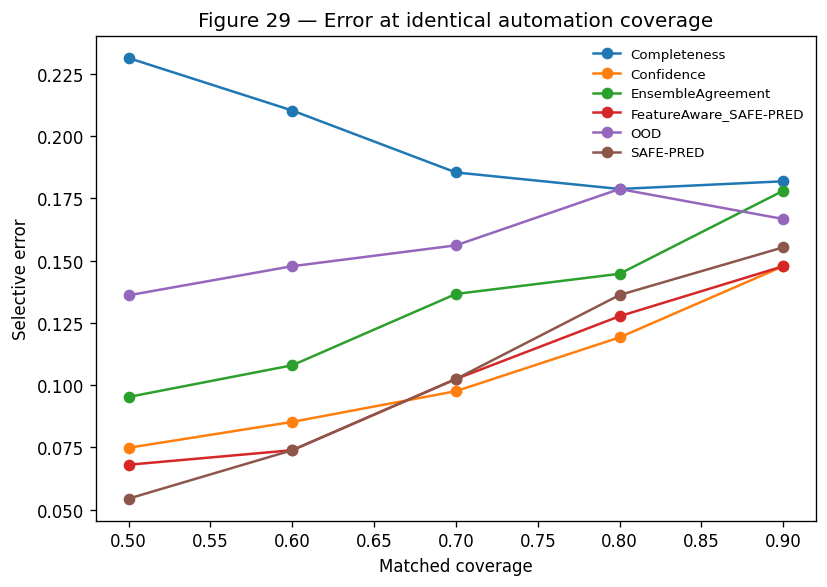

In [37]:
coverage_targets=[.50,.60,.70,.80,.90]; rows=[]
for name,s in method_scores_h.items():
    for cov in coverage_targets:
        m=metrics_at_coverage(yh,p_h,s,cov); m['Method']=name; rows.append(m)
matched=pd.DataFrame(rows); display(matched.pivot(index='coverage_target',columns='Method',values='selective_error').round(4)); matched.to_csv(OUT/'table_matched_coverage_external.csv',index=False)
fig,ax=plt.subplots(figsize=(7,5))
for name,g in matched.groupby('Method'): ax.plot(g.coverage_target,g.selective_error,'o-',label=name)
ax.set_xlabel('Matched coverage'); ax.set_ylabel('Selective error'); ax.set_title('Figure 29 — Error at identical automation coverage'); ax.legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'fig29_matched_coverage_error.png',dpi=300); plt.show()


## 28. Paired bootstrap: Feature-Aware SAFE-PRED vs original SAFE-PRED

Negative error differences favor Feature-Aware SAFE-PRED.


,Coverage,Difference_FeatureAware_minus_SAFE,CI_2.5,CI_97.5
0,0.5,0.0068,-0.0204,0.0272
1,0.6,0.0000,-0.0227,0.0284
2,0.7,0.0000,-0.0244,0.0244
3,0.8,-0.0043,-0.0213,0.0129
4,0.9,-0.0076,-0.0227,0.0114


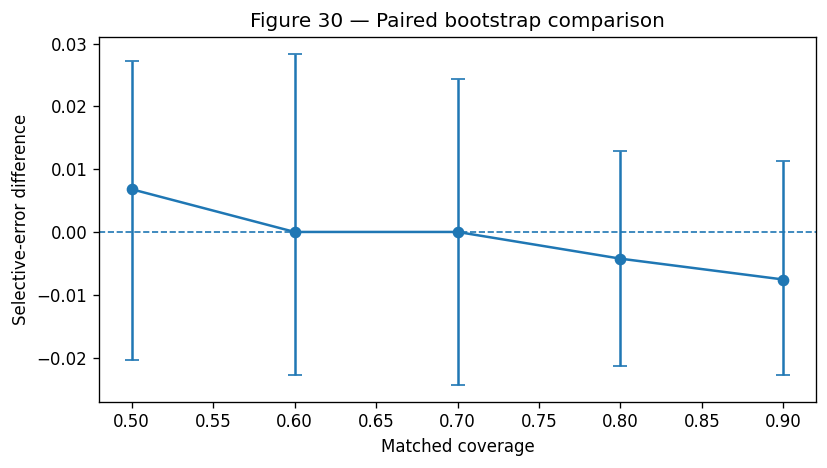

In [38]:
def paired_boot(y,p,sa,sb,cov,B=2000,seed=SEED):
    rng=np.random.default_rng(seed); y=np.asarray(y); p=np.asarray(p); sa=np.asarray(sa); sb=np.asarray(sb); n=len(y); vals=[]
    k=max(5,int(np.floor(n*cov)))
    for _ in range(B):
        idx=rng.integers(0,n,n); yy=y[idx]; pp=p[idx]; a=sa[idx]; b=sb[idx]
        ia=np.argsort(-a)[:k]; ib=np.argsort(-b)[:k]; vals.append(classification_error(yy[ia],pp[ia])-classification_error(yy[ib],pp[ib]))
    return np.quantile(vals,[.025,.5,.975])
rows=[]
for cov in coverage_targets:
    q=paired_boot(yh,p_h,fa_h,safe_h,cov,seed=SEED+int(cov*100)); rows.append({'Coverage':cov,'Difference_FeatureAware_minus_SAFE':q[1],'CI_2.5':q[0],'CI_97.5':q[2]})
paired_cmp=pd.DataFrame(rows); display(paired_cmp.round(4)); paired_cmp.to_csv(OUT/'table_paired_bootstrap_featureaware_vs_safe.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4)); med=paired_cmp.Difference_FeatureAware_minus_SAFE.to_numpy(); lo=med-paired_cmp['CI_2.5'].to_numpy(); hi=paired_cmp['CI_97.5'].to_numpy()-med
ax.errorbar(paired_cmp.Coverage,med,yerr=[lo,hi],fmt='o-',capsize=4); ax.axhline(0,linestyle='--',linewidth=1); ax.set_xlabel('Matched coverage'); ax.set_ylabel('Selective-error difference'); ax.set_title('Figure 30 — Paired bootstrap comparison')
plt.tight_layout(); plt.savefig(OUT/'fig30_paired_bootstrap_featureaware.png',dpi=300); plt.show()


## 29. High-confidence errors

High-confidence errors are wrong predictions made with max class probability ≥0.90. We test whether the deferral methods capture these particularly concerning failures.


In [39]:
rows=[]
for method,acc in [('SAFE-PRED',accept_h),('FeatureAware_SAFE-PRED',accept_fa_h)]:
    d=high_confidence_error_stats(yh,p_h,acc,.90); d.update({'Scenario':'Clean','Method':method}); rows.append(d)
for frac in [.10,.20,.30,.40]:
    z=degrade_random(Xh,frac,SEED+7000+int(frac*1000)); p=calibrated10.predict_proba(z)[:,1]; rz=iso.score_samples(pre_ood.transform(z))
    for method,s,t in [('SAFE-PRED',safe_score(p,z,rz),SAFE_THRESHOLD),('FeatureAware_SAFE-PRED',feature_aware_score(p,z,rz),FA_THRESHOLD)]:
        d=high_confidence_error_stats(yh,p,s>=t,.90); d.update({'Scenario':f'{int(frac*100)}% missing','Method':method}); rows.append(d)
hce_table=pd.DataFrame(rows); display(hce_table.round(4)); hce_table.to_csv(OUT/'table_high_confidence_errors.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
for method,g in hce_table.groupby('Method'): ax.plot(g.Scenario,g.HCE_deferred_fraction,'o-',label=method)
ax.set_ylim(0,1); ax.set_ylabel('Fraction of high-confidence errors deferred'); ax.set_title('Figure 31 — High-confidence-error capture'); ax.tick_params(axis='x',rotation=30); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig31_high_confidence_error_capture.png',dpi=300); plt.show()


ValueError: operands could not be broadcast together with shapes (294,) (5,) 

## 30. Feature-aware progressive degradation

Both SAFE-PRED variants use thresholds frozen from Cleveland. Hungarian is progressively degraded without retuning.


In [ ]:
rows=[]
for frac in [0,.05,.10,.20,.30,.40]:
    z=degrade_random(Xh,frac,SEED+8000+int(frac*1000)); p=calibrated10.predict_proba(z)[:,1]; rz=iso.score_samples(pre_ood.transform(z))
    for method,s,t in [('SAFE-PRED',safe_score(p,z,rz),SAFE_THRESHOLD),('FeatureAware_SAFE-PRED',feature_aware_score(p,z,rz),FA_THRESHOLD)]:
        a=s>=t; m=binary_metrics(yh,p); rows.append({'Method':method,'MissingFrac':frac,**m,'Coverage':a.mean(),'SelectiveError':classification_error(yh[a],p[a]) if a.sum()>=5 else np.nan,'ErrorCapture':capture_rate_of_errors(yh,p,a)})
fa_deg=pd.DataFrame(rows); display(fa_deg.round(4)); fa_deg.to_csv(OUT/'table_featureaware_external_degradation.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4.5))
for method,g in fa_deg.groupby('Method'): ax.plot(100*g.MissingFrac,g.SelectiveError,'o-',label=method)
ax.set_xlabel('Additional missingness (%)'); ax.set_ylabel('Selective error'); ax.set_title('Figure 32 — Selective error under degradation'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig32_featureaware_degradation_error.png',dpi=300); plt.show()
fig,ax=plt.subplots(figsize=(7,4.5))
for method,g in fa_deg.groupby('Method'): ax.plot(100*g.MissingFrac,g.Coverage,'o-',label=method)
ax.set_xlabel('Additional missingness (%)'); ax.set_ylabel('Coverage'); ax.set_ylim(0,1); ax.set_title('Figure 33 — Automation retained under degradation'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig33_featureaware_degradation_coverage.png',dpi=300); plt.show()


## 31. Fairness with bootstrap confidence intervals

We estimate uncertainty for sex-group differences in coverage, sensitivity, and selective error. Small subgroup size is treated as a limitation rather than hidden.


In [ ]:
def boot_group_diff(df,y,p,score,threshold,gcol,g1,g2,stat,B=2000,seed=SEED):
    rng=np.random.default_rng(seed); group=df[gcol].astype(str).to_numpy(); i1=np.where(group==str(g1))[0]; i2=np.where(group==str(g2))[0]; vals=[]
    def calc(idx):
        yy=np.asarray(y)[idx]; pp=np.asarray(p)[idx]; ss=np.asarray(score)[idx]; aa=ss>=threshold; pred=(pp>=.5).astype(int)
        if stat=='coverage': return aa.mean()
        if stat=='sensitivity':
            pos=yy==1; return np.mean(pred[pos]==1) if pos.sum() else np.nan
        if stat=='selective_error': return np.mean(pred[aa]!=yy[aa]) if aa.sum()>=5 else np.nan
    for _ in range(B):
        a=calc(rng.choice(i1,len(i1),replace=True)); b=calc(rng.choice(i2,len(i2),replace=True))
        if np.isfinite(a) and np.isfinite(b): vals.append(a-b)
    return np.quantile(vals,[.025,.5,.975]) if vals else [np.nan]*3
rows=[]
for method,s,t in [('SAFE-PRED',safe_h,SAFE_THRESHOLD),('FeatureAware_SAFE-PRED',fa_h,FA_THRESHOLD)]:
    for stat in ['coverage','sensitivity','selective_error']:
        q=boot_group_diff(hf,yh,p_h,s,t,'sex_group','Female','Male',stat,seed=SEED+len(rows)); rows.append({'Method':method,'Comparison':'Female - Male','Metric':stat,'CI_2.5':q[0],'MedianDifference':q[1],'CI_97.5':q[2]})
fair_boot=pd.DataFrame(rows); display(fair_boot.round(4)); fair_boot.to_csv(OUT/'table_fairness_bootstrap_sex.csv',index=False)
print('Age-group counts'); display(hf.age_group.astype(str).value_counts().to_frame('n'))
fig,ax=plt.subplots(figsize=(8,4)); med=fair_boot.MedianDifference.to_numpy(); lo=med-fair_boot['CI_2.5'].to_numpy(); hi=fair_boot['CI_97.5'].to_numpy()-med; x=np.arange(len(fair_boot))
ax.errorbar(x,med,yerr=[lo,hi],fmt='o',capsize=4); ax.axhline(0,linestyle='--',linewidth=1); ax.set_xticks(x); ax.set_xticklabels(fair_boot.Method+' | '+fair_boot.Metric,rotation=35,ha='right'); ax.set_ylabel('Female − Male difference'); ax.set_title('Figure 34 — Bootstrap uncertainty for sex disparities')
plt.tight_layout(); plt.savefig(OUT/'fig34_fairness_bootstrap_sex.png',dpi=300); plt.show()


## 32. Exploratory Operational Reliability / Safe Automation Envelope

This is **not clinical certification**. It is a pre-specified research operating envelope requiring:
- selective error ≤10%;
- sensitivity ≥0.75;
- Brier ≤0.15;
- sex coverage gap ≤0.15 where estimable.

We report the maximum coverage satisfying all criteria under increasing degradation.


In [ ]:
ERROR_MAX=.10; SENS_MIN=.75; BRIER_MAX=.15; SEX_GAP_MAX=.15
def envelope(y,p,score,group,grid=np.linspace(.30,1,71)):
    y=np.asarray(y); p=np.asarray(p); score=np.asarray(score); group=np.asarray(group).astype(str); rows=[]
    for cov in grid:
        k=max(5,int(np.floor(len(y)*cov))); idx=np.argsort(-score)[:k]; yy=y[idx]; pp=p[idx]; pred=(pp>=.5).astype(int); err=np.mean(pred!=yy); brier=brier_score_loss(yy,pp); pos=yy==1; sens=np.mean(pred[pos]==1) if pos.sum() else np.nan
        sel=np.zeros(len(y),bool); sel[idx]=True; cg=[]
        for g in np.unique(group):
            gm=group==g
            if gm.sum()>=20: cg.append(sel[gm].mean())
        gap=max(cg)-min(cg) if len(cg)>=2 else np.nan
        ok=err<=ERROR_MAX and sens>=SENS_MIN and brier<=BRIER_MAX and (np.isnan(gap) or gap<=SEX_GAP_MAX)
        rows.append({'coverage':k/len(y),'selective_error':err,'sensitivity':sens,'Brier':brier,'sex_coverage_gap':gap,'meets_envelope':ok})
    return pd.DataFrame(rows)
rows=[]
for frac in [0,.10,.20,.30,.40]:
    z=degrade_random(Xh,frac,SEED+9000+int(frac*1000)); p=calibrated10.predict_proba(z)[:,1]; rz=iso.score_samples(pre_ood.transform(z))
    for method,s in [('SAFE-PRED',safe_score(p,z,rz)),('FeatureAware_SAFE-PRED',feature_aware_score(p,z,rz))]:
        e=envelope(yh,p,s,hf.sex_group.astype(str).to_numpy()); f=e[e.meets_envelope]; rows.append({'Method':method,'MissingFrac':frac,'MaxEnvelopeCoverage':f.coverage.max() if len(f) else 0.0})
envelope_summary=pd.DataFrame(rows); display(envelope_summary.round(4)); envelope_summary.to_csv(OUT/'table_operational_reliability_envelope.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4.5))
for method,g in envelope_summary.groupby('Method'): ax.plot(100*g.MissingFrac,100*g.MaxEnvelopeCoverage,'o-',label=method)
ax.set_xlabel('Additional missingness (%)'); ax.set_ylabel('Max coverage satisfying envelope (%)'); ax.set_ylim(0,100); ax.set_title('Figure 35 — Operational reliability envelope'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig35_operational_reliability_envelope.png',dpi=300); plt.show()


## 33. Importance is not indispensability

Permutation importance is compared with Clinical Information Criticality. The paper should distinguish a feature that is often useful from a feature whose absence actually damages reliable deployment.


In [ ]:
crit_compare=pd.DataFrame({'Feature':CORE_10,'DevelopmentCriticality':[criticality_map[f] for f in CORE_10],'ExternalPermutationImportance':[imp_clean.get(f,0) for f in CORE_10]}).merge(single_ext[['Feature','Delta_AUROC','Delta_Brier']],on='Feature',how='left')
rho_imp,p_imp=spearmanr(crit_compare.ExternalPermutationImportance,crit_compare.Delta_AUROC); rho_cr,p_cr=spearmanr(crit_compare.DevelopmentCriticality,crit_compare.Delta_AUROC)
print(f'Permutation importance vs external damage: rho={rho_imp:.3f}, p={p_imp:.4f}'); print(f'Criticality vs external damage: rho={rho_cr:.3f}, p={p_cr:.4f}'); display(crit_compare.round(4)); crit_compare.to_csv(OUT/'table_importance_vs_criticality.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5)); ax.scatter(crit_compare.ExternalPermutationImportance,crit_compare.Delta_AUROC,label='Permutation importance'); ax.scatter(crit_compare.DevelopmentCriticality,crit_compare.Delta_AUROC,label='Criticality'); ax.set_xlabel('Score'); ax.set_ylabel('External AUROC loss under removal'); ax.set_title('Figure 36 — Importance vs indispensability'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'fig36_importance_vs_indispensability.png',dpi=300); plt.show()


## 34. Upgraded manuscript-ready summary and automatic finding flags

The automatic flags do not claim novelty. They identify which hypotheses are supported so the final paper framing can be based on actual results rather than expectations.


In [ ]:
def accepted_metrics(y,p,a):
    if np.sum(a)<5: return {}
    m=binary_metrics(np.asarray(y)[a],np.asarray(p)[a]); m['Coverage']=np.mean(a); m['SelectiveError']=classification_error(np.asarray(y)[a],np.asarray(p)[a]); return m
m_safe=accepted_metrics(yh,p_h,accept_h); m_fa=accepted_metrics(yh,p_h,accept_fa_h)
upgraded_summary=pd.DataFrame([{'Analysis':'Hungarian full cohort',**external_all,'Coverage':1.0,'SelectiveError':classification_error(yh,p_h)}, {'Analysis':'Original SAFE-PRED accepted',**m_safe}, {'Analysis':'Feature-Aware SAFE-PRED accepted',**m_fa}])
display(upgraded_summary.round(4)); upgraded_summary.to_csv(OUT/'table_upgraded_primary_summary.csv',index=False)
aurc_map=selective_summary.set_index('Method').AURC.to_dict(); hi=critical_dropout[critical_dropout.Scenario=='High-criticality'].set_index('N_features_removed'); lo=critical_dropout[critical_dropout.Scenario=='Low-criticality'].set_index('N_features_removed'); common=hi.index.intersection(lo.index)
flags={
'FeatureAware_lower_AURC_than_SAFE':aurc_map.get('FeatureAware_SAFE-PRED',np.inf)<aurc_map.get('SAFE-PRED',np.inf),
'FeatureAware_lower_error_majority_matched_coverages':bool((paired_cmp.Difference_FeatureAware_minus_SAFE<0).sum()>=3),
'Criticality_transfers_positive':bool(np.isfinite(rho_crit) and rho_crit>0),
'High_criticality_dropout_more_harmful':bool((hi.loc[common,'AUROC'].to_numpy()<lo.loc[common,'AUROC'].to_numpy()).sum()>=max(1,len(common)//2))
}
display(pd.Series(flags,name='Supported_by_results')); pd.Series(flags,name='Supported_by_results').to_csv(OUT/'finding_flags.csv')


## 35. SAFE-PRED 2.0 leakage checklist

- Development and cross-center evaluation cohorts are separate clinical-center files from UCI.
- Exact feature-record overlap is checked before external evaluation.
- Imputation, scaling, and encoding remain inside training pipelines.
- Hyperparameter selection uses Cleveland only.
- Development probabilities are cross-fitted/OOF.
- Feature criticality is learned from Cleveland only.
- Feature-Aware reliability weights are selected from Cleveland only.
- SAFE-PRED and Feature-Aware thresholds are selected from Cleveland only.
- Hungarian labels do not tune models, weights, criticality, or thresholds.
- External ablations are evaluation-only.
- Selective methods are compared at matched coverage.
- AURC/E-AURC complement risk–coverage plots.
- Fairness is reported with uncertainty and not overclaimed.
- “Safe automation” is explicitly experimental, not clinical certification.


## 36. Recommended final paper figures

**Main paper:**
1. Cohort missingness / cross-center shift.
2. Cleveland→Hungarian discrimination and calibration.
3. Progressive information-degradation response.
4. Clinical Information Criticality Map.
5. High-vs-low criticality loss at equal missingness.
6. Matched-coverage comparison of selective methods.
7. Original vs Feature-Aware SAFE-PRED under degradation.
8. Operational Reliability Envelope.
9. Fairness disparities with bootstrap CIs.

**Supplement:** model comparisons, raw risk–coverage plots, explanation stability, high-confidence-error capture, full-13 sensitivity analysis, and importance-vs-indispensability.


In [ ]:
config={'seed':SEED,'development_cohort':'UCI Cleveland Heart Disease','external_cohort':'UCI Hungarian Heart Disease','features_primary':CORE_10,'features_sensitivity':FEATURES_13,'selected_model':best_name10,'safe_threshold':float(SAFE_THRESHOLD),'feature_aware_threshold':float(FA_THRESHOLD),'feature_aware_weights':{k:float(v) for k,v in BEST_W.items()},'criticality_map':{k:float(v) for k,v in criticality_map.items()},'envelope':{'selective_error_max':ERROR_MAX,'sensitivity_min':SENS_MIN,'brier_max':BRIER_MAX,'sex_coverage_gap_max':SEX_GAP_MAX}}
with open(OUT/'analysis_config.json','w') as f: json.dump(config,f,indent=2)
print('Saved analysis_config.json')


## 37. ZIP every generated table and figure

On Kaggle this creates `/kaggle/working/safe_pred_outputs.zip`.


In [ ]:
import shutil
zip_base='/kaggle/working/safe_pred_outputs' if Path('/kaggle/working').exists() else str(OUT.resolve())
zip_file=shutil.make_archive(zip_base,'zip',str(OUT))
print('ZIP created:',zip_file)
print('Files included:')
for p in sorted(OUT.iterdir()): print(' -',p.name)


## 38. Original SAFE-PRED summary and export manifest
This cell creates a compact table of primary results and lists every saved figure/table.


In [ ]:
final_summary=pd.DataFrame({
    'Analysis':['Cleveland OOF core10','Hungarian all','Hungarian SAFE-PRED accepted'],
    'AUROC':[roc_auc_score(cleveland.target,p_oof10), external_all['AUROC'], external_sel.get('AUROC',np.nan)],
    'AUPRC':[average_precision_score(cleveland.target,p_oof10), external_all['AUPRC'], external_sel.get('AUPRC',np.nan)],
    'Brier':[brier_score_loss(cleveland.target,p_oof10), external_all['Brier'], external_sel.get('Brier',np.nan)],
    'Coverage':[1.0,1.0,accept_h.mean()]
})
display(final_summary.round(3))
final_summary.to_csv(OUT/'table_primary_summary.csv',index=False)

manifest=sorted([p.name for p in OUT.iterdir()])
print('Saved outputs:')
for f in manifest: print(' -',f)

## 39. Original leakage checklist

- **No global imputation/scaling/encoding before CV.** All preprocessing is fitted inside training folds.
- **No SMOTE before CV.** This notebook does not use SMOTE by default.
- **Nested CV** is used for the reported Cleveland model benchmark.
- **Hungarian labels are not used** for model family selection, hyperparameter tuning, calibration, SAFE-PRED weighting, OOD fitting, or deferral-threshold selection.
- **Exact overlap audit** is performed before cross-center validation.
- **Random/structured degradation is applied to test data only** in CV stress tests.
- **Fairness is reported descriptively** and not overstated because subgroup sizes are limited.
- **Core-10 is the primary cross-center feature set** because `slope`, `ca`, and `thal` are extremely sparse in Hungarian; full-13 transfer is a sensitivity analysis.
- **Statlog is not used as an independent validation set** because published audits have found it to be a Cleveland subset/reformat.
- **This historical benchmark is not claimed to be clinically deployment-ready.** The contribution is the reliability/deferral evaluation framework.


## 40. Original figure recommendations

1. Cohort/class distribution  
2. Missingness profile  
3. Feature-distribution shift  
4. Correlation structure  
5. Shift audit  
6. Nested-CV model comparison  
7. OOF ROC  
8. OOF PR  
9. Calibration curve  
10. Random-degradation performance  
11. Random-degradation Brier score  
12. Clinical-domain dropout  
13. Development risk–coverage  
14. Reliability vs correctness  
15. External ROC/PR  
16. External calibration  
17. External risk–coverage  
18–19. Fairness plots  
20. External degradation  
21. Explanation stability

**Primary paper focus:** risk–coverage, calibration under degradation, external/cross-center robustness, and fairness of deferral — not leaderboard accuracy.


In [ ]:
import shutil

shutil.make_archive(
    "/kaggle/working/safe_pred_outputs",
    "zip",
    "/kaggle/working/safe_pred_outputs"
)

print("/kaggle/working/safe_pred_outputs.zip")